## Trabalho 2 da disciplina de Aprendizado de Máquina Profundo

#### Rede Neural Convolucional (CNN) para uma tarefa de regressão a partir de imagens. O dataset fornecido consiste em imagens de bovinos acompanhadas de anotações referentes a características físicas dos animais. O objetivo do trabalho é desenvolver um modelo capaz de estimar, a partir de uma imagem, simultaneamente a altura (cm) e o peso (kg) do animal.


In [1]:
import csv
from pathlib import Path
import pandas as pd
from skimage import io
import numpy as np
import matplotlib.pyplot as plt

#### 1. Faça o download do dataset em https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_8.zip. Utilize !wget e !unzip para acessar os dados via Google Colab. O conjunto de dados contém um diretório images, com as imagens dos animais, e um arquivo annotations.csv, contendo as respectivas anotaçoes. A primeira coluna do arquivo annotations.csv identifica a imagem correspondente, enquanto a segunda e a terceira colunas contem, respectivamente, os valores de altura e peso associados a imagem. Utilize o modulo csv para leitura das anotacoes e o modulo skimage.io para leitura das imagens.


In [3]:
# !wget https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_8.zip

In [8]:
# !unzip dataset_8.zip

### leitura das anotações


In [2]:
pasta_dados = Path(".")
pasta_imagens = pasta_dados / "images"
arquivo_anotacoes = pasta_dados / "annotations.csv"

In [3]:
anotacoes = []

with arquivo_anotacoes.open(newline="", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo)

    for identificador, altura, peso in leitor:
        anotacoes.append({
            "id": identificador,
            "altura_cm": float(altura),
            "peso_kg": float(peso),
        })

print("número de anotações:", len(anotacoes))
anotacoes[:3]

número de anotações: 513


[{'id': '001', 'altura_cm': 123.0, 'peso_kg': 279.0},
 {'id': '002', 'altura_cm': 130.0, 'peso_kg': 296.0},
 {'id': '003', 'altura_cm': 112.0, 'peso_kg': 212.0}]

In [4]:
arquivos_imagens = sorted(pasta_imagens.iterdir())

for anotacao in anotacoes:
    anotacao["caminho"] = pasta_imagens / f"{anotacao['id']}.jpg"

caminhos_anotados = {anotacao["caminho"] for anotacao in anotacoes}

arquivos_sem_anotacao = [caminho for caminho in arquivos_imagens if caminho not in caminhos_anotados]

print("imagens sem anotação:", len(arquivos_sem_anotacao))
for caminho in arquivos_sem_anotacao:
    print(caminho.name)

imagens sem anotação: 1
334.jpg


tem 514 imagens e 513 anotações. a imagem `334.jpg` não tem anotação e fica fora do conjunto de dados. vamos usar as anotações como referência para selecionar e ordenar as imagens.


In [5]:
df = pd.DataFrame(anotacoes)
df.shape

(513, 4)

In [13]:
df.head()

,id,altura_cm,peso_kg,caminho
0,001,123.0,279.0,images/001.jpg
1,002,130.0,296.0,images/002.jpg
2,003,112.0,212.0,images/003.jpg
3,004,110.0,202.0,images/004.jpg
4,005,114.0,205.0,images/005.jpg


In [14]:
df.isna().sum()

id           0
altura_cm    0
peso_kg      0
caminho      0
dtype: int64

In [15]:
df["id"].duplicated().sum()

np.int64(0)

### plot de algumas das imagens


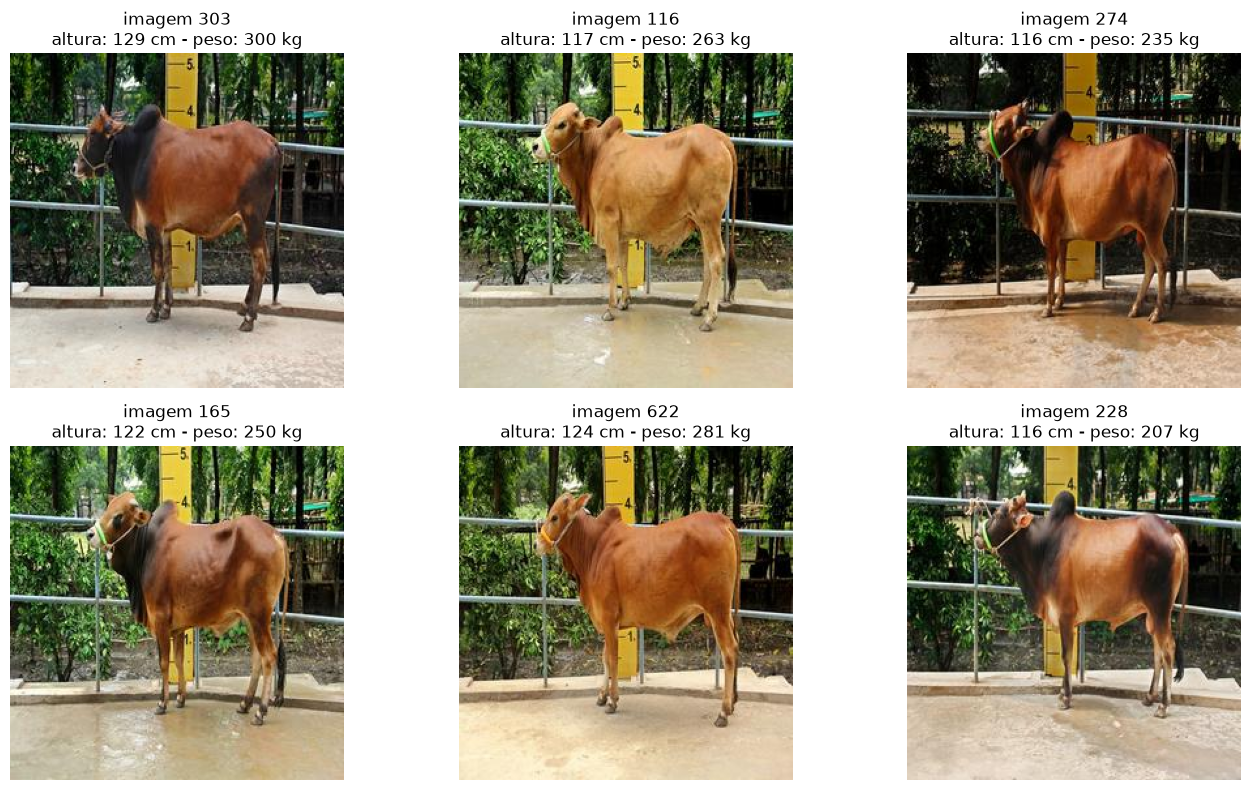

In [16]:
imagens_random = df.sample(n=6, random_state=7)

fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for eixo, (_, linha) in zip(eixos.flat, imagens_random.iterrows()):
    imagem = io.imread(linha["caminho"])
    eixo.imshow(imagem)
    eixo.set_title(f"imagem {linha['id']}\naltura: {linha['altura_cm']:.0f} cm - peso: {linha['peso_kg']:.0f} kg")
    eixo.axis("off")

plt.tight_layout()
plt.show()

### estatísticas dos rótulos


In [12]:
df[["altura_cm", "peso_kg"]].describe()

,altura_cm,peso_kg
count,513.000000,513.000000
mean,118.530214,256.029240
std,8.220566,74.300259
min,97.000000,150.000000
25%,113.000000,213.000000
50%,118.000000,239.000000
75%,123.000000,273.000000
max,148.000000,816.000000


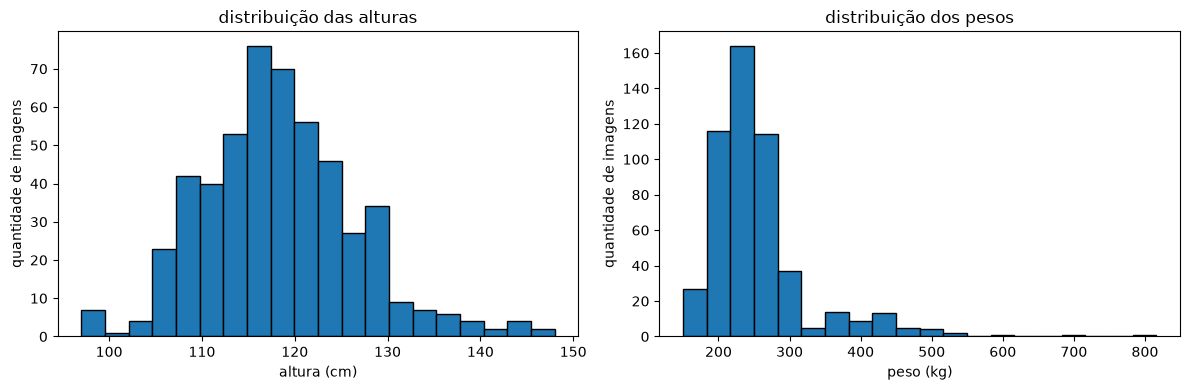

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].hist(df["altura_cm"], bins=20, edgecolor="black")
eixos[0].set(title="distribuição das alturas", xlabel="altura (cm)", ylabel="quantidade de imagens")

eixos[1].hist(df["peso_kg"], bins=20, edgecolor="black")
eixos[1].set(title="distribuição dos pesos", xlabel="peso (kg)", ylabel="quantidade de imagens")

plt.tight_layout()
plt.show()

pelos histogramas, as alturas têm uma distribuição aproximadamente simétrica. os pesos se concentram entre 200 e 300 kg, com uma cauda à direita em direção aos animais mais pesados.


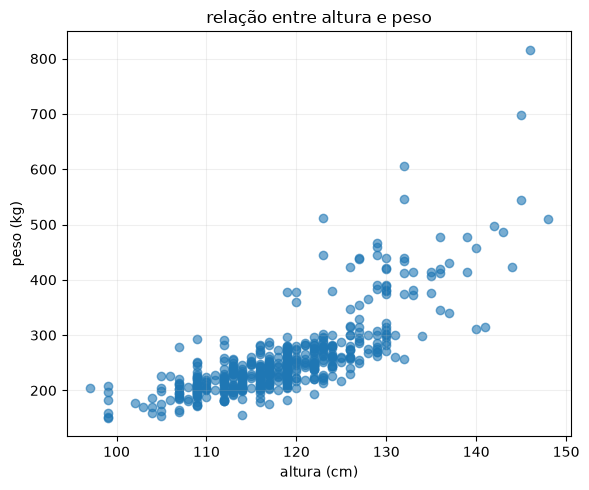

In [14]:
plt.figure(figsize=(6, 5))

plt.scatter(df["altura_cm"], df["peso_kg"], alpha=0.6)
plt.xlabel("altura (cm)")
plt.ylabel("peso (kg)")
plt.title("relação entre altura e peso")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

o gráfico indica uma associação positiva, os bovinos mais altos tendem a ser mais pesados.


#### 2. Trabalhe sobre o conjunto de dados, normalizando os valores dos pixels e realizando uma divisao dos dados para criar conjuntos independentes de treino e validacao. Considere as 50 primeiras imagens de annotations.csv como pertencendo ao conjunto de validacao e as demais pertencentes ao conjunto de treino.


### divisão em treino e validação


In [6]:
df_val = df.iloc[:50].copy()
df_treino = df.iloc[50:].copy()

print("# amostras de treino:", len(df_treino))
print("# amostras de validação:", len(df_val))

# amostras de treino: 463
# amostras de validação: 50


### formato e escala das imagens


In [7]:
formatos = set()
tipos = set()
pixel_min = 255
pixel_max = 0

for caminho in df["caminho"]:
    imagem = io.imread(caminho)

    formatos.add(imagem.shape)
    tipos.add(str(imagem.dtype))
    pixel_min = min(pixel_min, imagem.min())
    pixel_max = max(pixel_max, imagem.max())

print("formatos:", formatos)
print("tipos:", tipos)
print(f"faixa dos pixels: {pixel_min} até {pixel_max}")

formatos: {(256, 256, 3)}
tipos: {'uint8'}
faixa dos pixels: 0 até 255


### carregamento e normalização

vamos converter as imagens para float32 e dividir os pixels por 255, deixando os valores entre 0 e 1. essa escala é fixa e será aplicada igualmente no treino e na validação, sem precisar calcular média e desvio padrão.

os rótulos permanecem nas unidades originais, [altura em cm, peso em kg].


In [8]:
def carrega_e_normaliza_dados(tabela):
    imagens = np.stack([io.imread(caminho) for caminho in tabela["caminho"]]).astype(np.float32) / 255.0
    rotulos = tabela[["altura_cm", "peso_kg"]].to_numpy(dtype=np.float32)

    return imagens, rotulos


X_train, y_train = carrega_e_normaliza_dados(df_treino)
X_val, y_val = carrega_e_normaliza_dados(df_val)

In [9]:
print("treino:", X_train.shape, y_train.shape)
print("validação:", X_val.shape, y_val.shape)
print("tipo das imagens:", X_train.dtype)
print("faixa dos valores do treino:", X_train.min(), X_train.max())
print("faixa dos valores da validação:", X_val.min(), X_val.max())

treino: (463, 256, 256, 3) (463, 2)
validação: (50, 256, 256, 3) (50, 2)
tipo das imagens: float32
faixa dos valores do treino: 0.0 1.0
faixa dos valores da validação: 0.0 1.0


### Enunciados 3 até 8, com os bônus 2, 3 e 4 (o bonus 1, Transfer Learning, fica separado em uma seção abaixo)


### Preparação dos rótulos e avaliação


In [10]:
media_y = y_train.mean(axis=0)
desvio_y = y_train.std(axis=0)
print("médias [altura, peso]:", media_y)
print("desvios [altura, peso]:", desvio_y)

médias [altura, peso]: [118.62635 258.37796]
desvios [altura, peso]: [ 8.395252 76.92018 ]


In [11]:
y_train_norm = (y_train - media_y) / desvio_y
y_val_norm = (y_val - media_y) / desvio_y
print("treino médias:", y_train_norm.mean(axis=0))
print("treino desvios:", y_train_norm.std(axis=0))
print("validação médias:", y_val_norm.mean(axis=0))
print("validação desvios:", y_val_norm.std(axis=0))

treino médias: [-6.1793152e-08  1.1534722e-07]
treino desvios: [1. 1.]
validação médias: [-0.11748907 -0.3132853 ]
validação desvios: [0.73880464 0.45358884]


In [12]:
def desnormaliza_rotulos(valores_norm):
    return np.asarray(valores_norm) * desvio_y + media_y

In [13]:
def avalia_predicao(y_real, y_hat):
    y_real = np.asarray(y_real, dtype=np.float64)
    y_hat = np.asarray(y_hat, dtype=np.float64)
    if y_real.shape != y_hat.shape:
        raise ValueError("os rótulos e predições devem ter o mesmo shape.")

    from sklearn.metrics import r2_score

    erros = y_hat - y_real
    mae = np.mean(np.abs(erros), axis=0)
    rmse = np.sqrt(np.mean(erros ** 2, axis=0))
    r2 = r2_score(y_real, y_hat, multioutput="raw_values")

    return mae, rmse, r2

um baseline para as cnns: chutar a média de altura e peso


In [23]:
previsoes_media = np.tile(media_y, (len(y_val), 1))

avalia_predicao(y_val, previsoes_media)

(array([ 5.06021606, 36.09701294]),
 array([ 6.28038909, 42.40322259]),
 array([-0.02528924, -0.47704048]))

- para altura: MAE de 5,06 cm, RMSE de 6,28 cm
- para peso: MAE de 36,10 kg, RMSE de 42,4 kg


### Implementação dos blocos convolucionais


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

tf.keras.utils.set_random_seed(7)
tf.config.experimental.enable_op_determinism()

2026-10-31 08:40:33.292623: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-31 08:40:33.563125: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-31 08:40:34.786485: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [15]:
# ResNet (2015), bloco padrão
def residual_block(x, filtros, stride=1, l2=0.0, usar_residual=True):
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    atalho = x

    # caminho principal: duas convoluções 3x3, com a primeira controlando a redução espacial (stride)
    x = layers.Conv2D(filtros, 3, strides=stride, padding="same", use_bias=False, 
                      kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False, 
                      kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)

    # adapta o atalho se a dimensao ou a quantidade de canais mudar
    if usar_residual:
        if stride != 1 or atalho.shape[-1] != filtros:
            atalho = layers.Conv2D(filtros, 1, strides=stride, padding="same", use_bias=False,
                                   kernel_initializer="he_normal", kernel_regularizer=regularizador)(atalho)
            atalho = layers.BatchNormalization()(atalho)

        # combina o caminho principal com o atalho antes da ativação final
        x = layers.Add()([x, atalho])

    return layers.ReLU()(x)

In [16]:
# Xception (2017) / MobileNet (2017)
def separable_residual_block(x, filtros, stride=1, l2=0.0, usar_residual=True):
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    atalho = x

    # caminho principal: duas SeparableConv2D 3x3
    # depthwise convolution, com um kernel 3x3 para cada canal de entrada, depois pointwise convolution (1x1xCinxK) para misturar a informação de todos canais
    x = layers.SeparableConv2D(filtros, 3, strides=stride, padding="same", use_bias=False, 
                               depthwise_initializer="he_normal", pointwise_initializer="he_normal", 
                               depthwise_regularizer=regularizador, pointwise_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.SeparableConv2D(filtros, 3, padding="same", use_bias=False, 
                               depthwise_initializer="he_normal", pointwise_initializer="he_normal", 
                               depthwise_regularizer=regularizador, pointwise_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)

    # adapta o atalho se a dimensão ou a quantidade de canais mudar
    if usar_residual:
        if stride != 1 or atalho.shape[-1] != filtros:
            atalho = layers.Conv2D(filtros, 1, strides=stride, padding="same", use_bias=False, 
                                   kernel_initializer="he_normal", kernel_regularizer=regularizador)(atalho)
            atalho = layers.BatchNormalization()(atalho)

        # combina o caminho principal com o atalho antes da ativação final
        x = layers.Add()([x, atalho])

    return layers.ReLU()(x)

In [17]:
# MobileNetV2 (2018)
def inverted_residual_block(x, filtros, stride=1, expansao=4, l2=0.0, usar_residual=True):
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    atalho = x
    canais_entrada = int(x.shape[-1])
    canais_expandidos = canais_entrada * expansao

    # expande os canais com uma convolução 1x1
    if expansao != 1:
        x = layers.Conv2D(canais_expandidos, 1, padding="same", use_bias=False, 
                          kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU(max_value=6)(x)

    # filtra cada canal separadamente com depthwise convolution nesse espaço de maior dimensão
    x = layers.DepthwiseConv2D(3, strides=stride, padding="same", use_bias=False,
                               depthwise_initializer="he_normal", depthwise_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6)(x)

    # projeta para os canais de saída (K filtros), sem ativação para evitar perda de info / manter o gargalo linear
    x = layers.Conv2D(filtros, 1, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador)(x)
    x = layers.BatchNormalization()(x)

    # soma a entrada somente quando as dimensões são iguais
    if usar_residual and stride == 1 and canais_entrada == filtros:
        x = layers.Add()([x, atalho])

    return x

### Construtor da CNN


In [18]:
def build_cnn(config):
    tipos_blocos = {
        "residual": residual_block,
        "separable": separable_residual_block,
        "inverted": inverted_residual_block,
    }

    tipo_bloco = config["tipo_bloco"]
    canais = config["canais"]
    blocos_por_estagio = config["blocos_por_estagio"]
    cabeca = config["cabeca"]
    l2 = config.get("l2", 0.0)
    dropout = config.get("dropout", 0.0)
    unidades_dense = config.get("unidades_dense", 64)
    regularizador = regularizers.l2(l2) if l2 > 0 else None

    entrada = tf.keras.Input(shape=config.get("input_shape", (256, 256, 3)), name="imagem")

    # convolução inicial, extrai características e reduz a dimensão pela metade
    x = layers.Conv2D(config.get("canais_iniciais", 24), 3, strides=2, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador, name="conv_inicial")(entrada)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # cada estágio reduz a resolução no primeiro bloco
    bloco = tipos_blocos[tipo_bloco]
    
    for filtros, quantidade in zip(canais, blocos_por_estagio):
        for indice in range(quantidade):
            argumentos = {
                "filtros": int(filtros),
                "stride": 2 if indice == 0 else 1,
                "l2": l2,
                "usar_residual": config.get("usar_residual", True),
            }

            if tipo_bloco == "inverted":
                argumentos["expansao"] = config.get("expansao", 4)

            x = bloco(x, **argumentos)

    # transforma os feature maps em um vetor de características usando global average pooling
    x = layers.GlobalAveragePooling2D(name="pooling_global")(x)

    def dense_layer(tensor, nome):
        tensor = layers.Dense(unidades_dense, activation="relu", kernel_initializer="he_normal",
            kernel_regularizer=regularizador, name=f"dense_{nome}")(tensor)

        if dropout > 0:
            tensor = layers.Dropout(dropout, name=f"dropout_{nome}")(tensor)

        return tensor

    if cabeca == "conjunta":
        # as duas tarefas compartilham também a camada densa
        x = dense_layer(x, "conjunta")
        saida = layers.Dense(2, name="predicoes")(x)
    else:
        # cada tarefa recebe sua própria transformação do vetor compartilhado
        altura = dense_layer(x, "altura")
        altura = layers.Dense(1, name="altura")(altura)

        peso = dense_layer(x, "peso")
        peso = layers.Dense(1, name="peso")(peso)

        saida = layers.Concatenate(name="predicoes")([altura, peso])

    modelo = tf.keras.Model(entrada, saida, name=f"cnn_{tipo_bloco}_{cabeca}")

    # inclui os parâmetros treináveis e não treináveis!
    total_parametros = modelo.count_params()
    if total_parametros > 5000000:
        raise ValueError(f"modelo com {total_parametros} parâmetros! o limite é 5.000.000!!!")

    return modelo

In [29]:
config_inicial = {
    "input_shape": tuple(X_train.shape[1:]),
    "tipo_bloco": "residual",
    "canais_iniciais": 24,
    "canais": (32, 64, 128, 192),
    "blocos_por_estagio": (2, 2, 2, 2),
    "cabeca": "conjunta",
    "unidades_dense": 64,
    "expansao": 4,
    "usar_residual": True,
    "dropout": 0.0,
    "l2": 0.0,
}

modelo = build_cnn(config_inicial)
modelo.summary()

I0000 00:00:1793320663.965333   40627 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4177 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "cnn_residual_conjunta"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagem (InputLayer) │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_inicial        │ (None, 128, 128,  │        648 │ imagem[0][0]      │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         96 │ conv_inicial[0][… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      6,912 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │        768 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu_3[0][0]   

 Total params: 1,953,322 (7.45 MB)

 Trainable params: 1,949,114 (7.44 MB)

 Non-trainable params: 4,208 (16.44 KB)

In [30]:
resultados_arquiteturas = []

for tipo_bloco in ("residual", "separable", "inverted"):
    for cabeca in ("conjunta", "separada"):
        config = {
            **config_inicial,
            "tipo_bloco": tipo_bloco,
            "cabeca": cabeca,
        }

        modelo_teste = build_cnn(config)
        saida = modelo_teste(X_train[:1], training=False)

        resultados_arquiteturas.append({
            "bloco": tipo_bloco,
            "cabeca": cabeca,
            "parametros": modelo_teste.count_params(),
            "saida": tuple(saida.shape),
        })

        del modelo_teste


pd.DataFrame(resultados_arquiteturas)

2026-10-29 21:37:44.906098: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90300


,bloco,cabeca,parametros,saida
0,residual,conjunta,1953322,"(1, 2)"
1,residual,separada,1965674,"(1, 2)"
2,separable,conjunta,281282,"(1, 2)"
3,separable,separada,293634,"(1, 2)"
4,inverted,conjunta,759306,"(1, 2)"
5,inverted,separada,771658,"(1, 2)"


### Treinamento inicial de uma CNN para teste


In [31]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

# usa a rede residual sem dropout ou l2 como um baseline simples de CNN
config_treino_inicial = {
    **config_inicial,
    "tipo_bloco": "residual",
    "cabeca": "conjunta",
    "dropout": 0.0,
    "l2": 0.0,
}

modelo = build_cnn(config_treino_inicial)
# minimiza o mse das duas saídas normalizadas usando adam
modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse")

print("número de parâmetros:", modelo.count_params())

número de parâmetros: 1953322


In [24]:
from time import perf_counter

In [ ]:
# callbacks de treinamento
# reduceLRonPlateau reduz o LR pela metade depois de 5 épocas sem melhorar a loss de val
# earlyStopping para o treinamento depois de 15 épocas sem melhorar a loss de val, recupera os pesos da época com menor val loss
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=15, restore_best_weights=True, verbose=1)
]


inicio_treino = perf_counter()

historico = modelo.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80, batch_size=16, 
                       shuffle=True, callbacks=callbacks, verbose=2)

tempo_total = perf_counter() - inicio_treino

Epoch 1/80


2026-10-29 21:37:47.465183: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-29 21:37:56.039374: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

29/29 - 9s - 318ms/step - loss: 1.2255 - val_loss: 103.6876 - learning_rate: 0.0010
Epoch 2/80
29/29 - 2s - 78ms/step - loss: 0.4609 - val_loss: 7.4362 - learning_rate: 0.0010
Epoch 3/80
29/29 - 2s - 78ms/step - loss: 0.2945 - val_loss: 0.6674 - learning_rate: 0.0010
Epoch 4/80
29/29 - 2s - 78ms/step - loss: 0.1974 - val_loss: 0.5608 - learning_rate: 0.0010
Epoch 5/80
29/29 - 2s - 78ms/step - loss: 0.1102 - val_loss: 0.2708 - learning_rate: 0.0010
Epoch 6/80
29/29 - 2s - 78ms/step - loss: 0.1361 - val_loss: 1.3148 - learning_rate: 0.0010
Epoch 7/80
29/29 - 2s - 78ms/step - loss: 0.1253 - val_loss: 0.3122 - learning_rate: 0.0010
Epoch 8/80
29/29 - 2s - 78ms/step - loss: 0.0908 - val_loss: 0.3807 - learning_rate: 0.0010
Epoch 9/80
29/29 - 2s - 78ms/step - loss: 0.1214 - val_loss: 0.5835 - learning_rate: 0.0010
Epoch 10/80

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
29/29 - 2s - 78ms/step - loss: 0.1454 - val_loss: 0.6220 - learning_rate: 0.0010
Epoch 11/

In [33]:
print("melhor val_loss:", min(historico.history["val_loss"]))
print(f"tempo total: {tempo_total / 60:.2f} min")

melhor val_loss: 0.15615567564964294
tempo total: 1.33 min


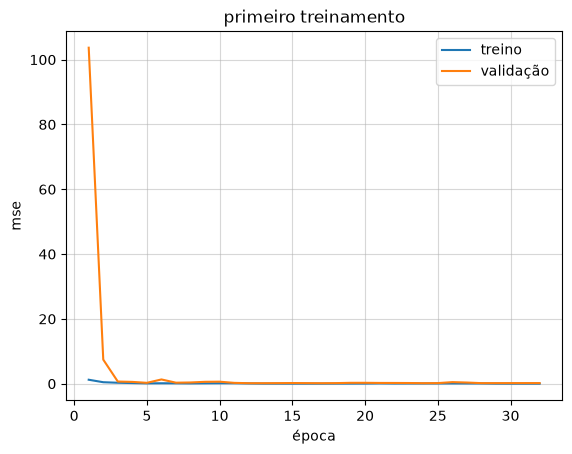

In [34]:
# compara as curvas de mse na escala normalizada, não em cm ou kg
epocas = np.arange(1, len(historico.history["loss"]) + 1)

plt.plot(epocas, historico.history["loss"], label="treino")
plt.plot(epocas, historico.history["val_loss"], label="validação")
plt.xlabel("época")
plt.ylabel("mse")
plt.title("primeiro treinamento")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

In [35]:
previsoes_norm = modelo.predict(X_val)
previsoes = desnormaliza_rotulos(previsoes_norm)

mae_cnn, rmse_cnn, r2_cnn = avalia_predicao(y_val, previsoes)

# compara com a previsão constante das médias do treino
previsoes_media = np.tile(media_y, (len(y_val), 1))
mae_media, rmse_media, r2_media = avalia_predicao(y_val, previsoes_media)

pd.DataFrame({
    "modelo": ["média do treino"] * 2 + ["cnn inicial"] * 2,
    "variável": ["altura", "peso"] * 2,
    "unidade": ["cm", "kg"] * 2,
    "mae": np.concatenate([mae_media, mae_cnn]),
    "rmse": np.concatenate([rmse_media, rmse_cnn]),
    "r2": np.concatenate([r2_media, r2_cnn]),
})

2026-10-29 21:39:06.614354: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 288ms/step


,modelo,variável,unidade,mae,rmse,r2
0,média do treino,altura,cm,5.060216,6.280389,-0.025289
1,média do treino,peso,kg,36.097013,42.403223,-0.477040
2,cnn inicial,altura,cm,3.228642,3.914780,0.601629
3,cnn inicial,peso,kg,18.121904,23.694345,0.538806


o primeiro modelo residual, com ~1,95 milhoes de parâmetros, melhorou os resultados em relação ao baseline de prever a média do treino. o MAE da altura caiu de 5,06 para 3,22 cm, e o do peso de 36,1 para 18,12 kg.

nas primeiras épocas, a loss de validação oscilou bastante. depois, o treino se estabilizou e atingiu a menor loss de validação na época 17, com MSE de aproximadamente 0,156.

a loss de treino se aproximou de zero, enquanto a de validação permaneceu em torno de 0,16, indicando sinal de overfitting. esse resultado serve como baseline para comparar os próximos modelos com data augmentation e regularização.


### Data augmentation e regularização


In [79]:
def build_augmentation(seed=7):
    return tf.keras.Sequential([
        layers.RandomContrast(factor=0.1, seed=seed),
        layers.RandomBrightness(factor=0.05, value_range=(0.0, 1.0), seed=seed + 1),
        layers.RandomFlip(mode="horizontal", seed=seed + 2,)
    ], name="augmentation")

I0000 00:00:1793329883.204677 3896956 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4078 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


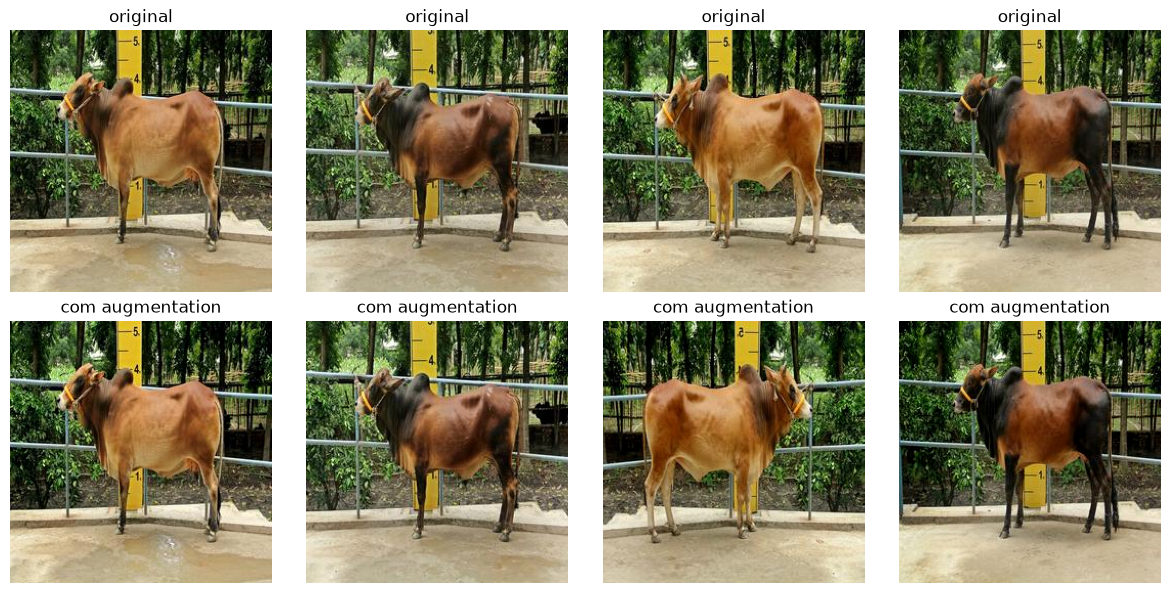

In [30]:
augmentation_preview = build_augmentation()

originais = X_train[:4]
transformadas = augmentation_preview(originais, training=True).numpy()

fig, eixos = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    eixos[0, i].imshow(originais[i])
    eixos[0, i].set_title("original")

    eixos[1, i].imshow(transformadas[i])
    eixos[1, i].set_title("com augmentation")

    eixos[0, i].axis("off")
    eixos[1, i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
def build_cnn(config):
    tipos_blocos = {
        "residual": residual_block,
        "separable": separable_residual_block,
        "inverted": inverted_residual_block,
    }

    tipo_bloco = config["tipo_bloco"]
    canais = config["canais"]
    blocos_por_estagio = config["blocos_por_estagio"]
    cabeca = config["cabeca"]
    l2 = config.get("l2", 0.0)
    dropout = config.get("dropout", 0.0)
    unidades_dense = config.get("unidades_dense", 64)
    regularizador = regularizers.l2(l2) if l2 > 0 else None

    entrada = tf.keras.Input(shape=config.get("input_shape", (256, 256, 3)), name="imagem")

    # transforma as imagens somente durante o treinamento
    x = entrada
    if config.get("augmentation", False):
        x = build_augmentation(seed=config.get("seed_augmentation", 7))(x)

    # convolução inicial, extrai características e reduz a dimensão pela metade
    x = layers.Conv2D(config.get("canais_iniciais", 24), 3, strides=2, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador, name="conv_inicial")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # cada estágio reduz a resolução no primeiro bloco
    bloco = tipos_blocos[tipo_bloco]
    
    for filtros, quantidade in zip(canais, blocos_por_estagio):
        for indice in range(quantidade):
            argumentos = {
                "filtros": int(filtros),
                "stride": 2 if indice == 0 else 1,
                "l2": l2,
                "usar_residual": config.get("usar_residual", True),
            }

            if tipo_bloco == "inverted":
                argumentos["expansao"] = config.get("expansao", 4)

            x = bloco(x, **argumentos)

    # transforma os feature maps em um vetor de características usando global average pooling
    x = layers.GlobalAveragePooling2D(name="pooling_global")(x)

    def dense_layer(tensor, nome):
        tensor = layers.Dense(unidades_dense, activation="relu", kernel_initializer="he_normal",
            kernel_regularizer=regularizador, name=f"dense_{nome}")(tensor)

        if dropout > 0:
            tensor = layers.Dropout(dropout, name=f"dropout_{nome}")(tensor)

        return tensor

    if cabeca == "conjunta":
        # as duas tarefas compartilham também a camada densa
        x = dense_layer(x, "conjunta")
        saida = layers.Dense(2, name="predicoes")(x)
    else:
        # cada tarefa recebe sua própria transformação do vetor compartilhado
        altura = dense_layer(x, "altura")
        altura = layers.Dense(1, name="altura")(altura)

        peso = dense_layer(x, "peso")
        peso = layers.Dense(1, name="peso")(peso)

        saida = layers.Concatenate(name="predicoes")([altura, peso])

    modelo = tf.keras.Model(entrada, saida, name=f"cnn_{tipo_bloco}_{cabeca}")

    # inclui os parâmetros treináveis e não treináveis!
    total_parametros = modelo.count_params()
    if total_parametros > 5000000:
        raise ValueError(f"modelo com {total_parametros} parâmetros! o limite é 5.000.000!!!")

    return modelo

In [39]:
comparacao_inicial = pd.DataFrame({
    "modelo": ["média do treino"] * 2 + ["cnn inicial"] * 2,
    "variável": ["altura", "peso"] * 2,
    "unidade": ["cm", "kg"] * 2,
    "mae": np.concatenate([mae_media, mae_cnn]),
    "rmse": np.concatenate([rmse_media, rmse_cnn]),
    "r2": np.concatenate([r2_media, r2_cnn]),
})

historico_inicial = historico.history.copy()

In [40]:
# testando agora no modelo inicial se o augmentation, sem dropout e l2, melhora

config_aug = {
    **config_treino_inicial,
    "augmentation": True,
    "seed_augmentation": 7,
    "dropout": 0.0,
    "l2": 0.0,
}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

modelo_aug = build_cnn(config_aug)
modelo_aug.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

In [41]:
callbacks_aug = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1,)
]

In [42]:
inicio_aug = perf_counter()

historico_aug = modelo_aug.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80,
                               batch_size=16, shuffle=True, callbacks=callbacks_aug, verbose=2)

tempo_aug = perf_counter() - inicio_aug

print(f"tempo total: {tempo_aug / 60:.2f} min")
print("melhor época:", np.argmin(historico_aug.history["val_mse_dados"]) + 1)

Epoch 1/80


2026-10-29 21:39:19.150681: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


29/29 - 10s - 345ms/step - loss: 1.2876 - mse_dados: 1.2876 - val_loss: 9.0278 - val_mse_dados: 9.0278 - learning_rate: 0.0010
Epoch 2/80
29/29 - 2s - 82ms/step - loss: 0.6231 - mse_dados: 0.6231 - val_loss: 7.2117 - val_mse_dados: 7.2117 - learning_rate: 0.0010
Epoch 3/80
29/29 - 2s - 82ms/step - loss: 0.3407 - mse_dados: 0.3407 - val_loss: 0.8769 - val_mse_dados: 0.8769 - learning_rate: 0.0010
Epoch 4/80
29/29 - 2s - 81ms/step - loss: 0.2610 - mse_dados: 0.2610 - val_loss: 0.8301 - val_mse_dados: 0.8301 - learning_rate: 0.0010
Epoch 5/80
29/29 - 2s - 81ms/step - loss: 0.2009 - mse_dados: 0.2009 - val_loss: 0.8439 - val_mse_dados: 0.8439 - learning_rate: 0.0010
Epoch 6/80
29/29 - 2s - 80ms/step - loss: 0.1294 - mse_dados: 0.1294 - val_loss: 0.4933 - val_mse_dados: 0.4933 - learning_rate: 0.0010
Epoch 7/80
29/29 - 2s - 81ms/step - loss: 0.1048 - mse_dados: 0.1048 - val_loss: 0.3579 - val_mse_dados: 0.3579 - learning_rate: 0.0010
Epoch 8/80
29/29 - 2s - 81ms/step - loss: 0.0813 - mse_da

In [43]:
previsoes_aug_norm = modelo_aug.predict(X_val, verbose=0)
previsoes_aug = desnormaliza_rotulos(previsoes_aug_norm)

mae_aug, rmse_aug, r2_aug = avalia_predicao(y_val, previsoes_aug)

comparacao_aug = pd.DataFrame({
    "modelo": ["cnn inicial"] * 2 + ["brilho, contraste e flip"] * 2,
    "variável": ["altura", "peso"] * 2,
    "mae": np.concatenate([mae_cnn, mae_aug]),
    "rmse": np.concatenate([rmse_cnn, rmse_aug]),
    "r2": np.concatenate([r2_cnn, r2_aug]),
})

comparacao_aug

2026-10-29 21:41:53.423973: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,modelo,variável,mae,rmse,r2
0,cnn inicial,altura,3.228642,3.914780,0.601629
1,cnn inicial,peso,18.121904,23.694345,0.538806
2,"brilho, contraste e flip",altura,2.740676,3.348631,0.708521
3,"brilho, contraste e flip",peso,18.323156,22.261551,0.592896


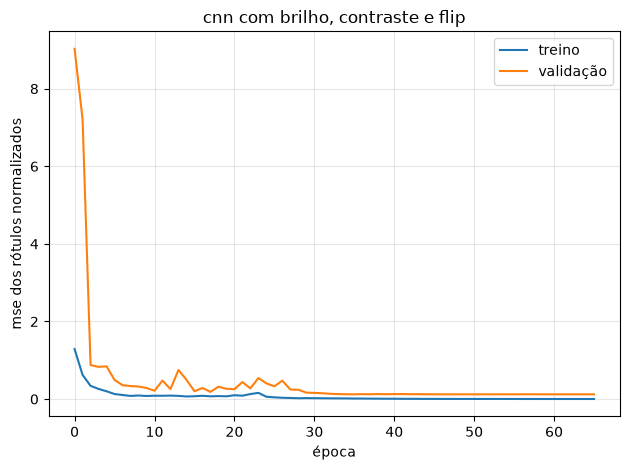

In [44]:
plt.plot(historico_aug.history["mse_dados"], label="treino")
plt.plot(historico_aug.history["val_mse_dados"], label="validação")

plt.xlabel("época")
plt.ylabel("mse dos rótulos normalizados")
plt.title("cnn com brilho, contraste e flip")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
comparacao_aug_sem_reg = comparacao_aug.copy()
historico_aug_sem_reg = historico_aug.history.copy()

In [46]:
# testando agora no modelo inicial se com augmentation e o dropout e l2 melhora

config_aug_reg = {
    **config_treino_inicial,
    "augmentation": True,
    "seed_augmentation": 7,
    "dropout": 0.2,
    "l2": 1e-5,
}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

modelo_aug_reg = build_cnn(config_aug_reg)
modelo_aug_reg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

In [47]:
callbacks_aug_reg = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1,)
]

In [48]:
inicio_aug_reg = perf_counter()

historico_aug_reg = modelo_aug_reg.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80,
                               batch_size=16, shuffle=True, callbacks=callbacks_aug_reg, verbose=2)

tempo_aug_reg = perf_counter() - inicio_aug_reg

print(f"tempo total: {tempo_aug_reg / 60:.2f} min")
print("melhor época:", np.argmin(historico_aug_reg.history["val_mse_dados"]) + 1)

Epoch 1/80


2026-10-29 21:42:04.780917: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


29/29 - 10s - 362ms/step - loss: 1.2031 - mse_dados: 1.1596 - val_loss: 122.8641 - val_mse_dados: 122.8203 - learning_rate: 0.0010
Epoch 2/80
29/29 - 2s - 83ms/step - loss: 0.7671 - mse_dados: 0.7232 - val_loss: 1.0386 - val_mse_dados: 0.9946 - learning_rate: 0.0010
Epoch 3/80
29/29 - 2s - 82ms/step - loss: 0.4916 - mse_dados: 0.4476 - val_loss: 0.6281 - val_mse_dados: 0.5840 - learning_rate: 0.0010
Epoch 4/80
29/29 - 2s - 83ms/step - loss: 0.3461 - mse_dados: 0.3020 - val_loss: 0.4859 - val_mse_dados: 0.4418 - learning_rate: 0.0010
Epoch 5/80
29/29 - 2s - 82ms/step - loss: 0.2999 - mse_dados: 0.2558 - val_loss: 0.3606 - val_mse_dados: 0.3165 - learning_rate: 0.0010
Epoch 6/80
29/29 - 2s - 82ms/step - loss: 0.2383 - mse_dados: 0.1942 - val_loss: 0.3119 - val_mse_dados: 0.2677 - learning_rate: 0.0010
Epoch 7/80
29/29 - 2s - 81ms/step - loss: 0.2479 - mse_dados: 0.2037 - val_loss: 0.2389 - val_mse_dados: 0.1947 - learning_rate: 0.0010
Epoch 8/80
29/29 - 2s - 82ms/step - loss: 0.2519 - ms

In [49]:
previsoes_aug_reg_norm = modelo_aug_reg.predict(X_val, verbose=0)
previsoes_aug_reg = desnormaliza_rotulos(previsoes_aug_reg_norm)

mae_aug_reg, rmse_aug_reg, r2_aug_reg = avalia_predicao(y_val, previsoes_aug_reg)

comparacao_aug_reg = pd.DataFrame({
    "modelo": ["cnn inicial"] * 2 + ["augmentation + l2 e dropout"] * 2,
    "variável": ["altura", "peso"] * 2,
    "mae": np.concatenate([mae_cnn, mae_aug_reg]),
    "rmse": np.concatenate([rmse_cnn, rmse_aug_reg]),
    "r2": np.concatenate([r2_cnn, r2_aug_reg]),
})

comparacao_aug_reg

2026-10-29 21:44:09.254487: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,modelo,variável,mae,rmse,r2
0,cnn inicial,altura,3.228642,3.914780,0.601629
1,cnn inicial,peso,18.121904,23.694345,0.538806
2,augmentation + l2 e dropout,altura,2.847261,3.475767,0.685968
3,augmentation + l2 e dropout,peso,19.119942,22.853735,0.570949


In [50]:
comparacao_regularizacao = pd.concat([
    comparacao_aug_sem_reg,
    comparacao_aug_reg[comparacao_aug_reg["modelo"] == "augmentation + l2 e dropout"],
], ignore_index=True)

comparacao_regularizacao

,modelo,variável,mae,rmse,r2
0,cnn inicial,altura,3.228642,3.914780,0.601629
1,cnn inicial,peso,18.121904,23.694345,0.538806
2,"brilho, contraste e flip",altura,2.740676,3.348631,0.708521
3,"brilho, contraste e flip",peso,18.323156,22.261551,0.592896
4,augmentation + l2 e dropout,altura,2.847261,3.475767,0.685968
5,augmentation + l2 e dropout,peso,19.119942,22.853735,0.570949


nessa config inicial, adicionar dropout de 0,2 e l2 de 1e-5 não trouxe uma melhora consistente em relação ao augmentation isolado. os efeitos variaram conforme a tarefa e a métrica, então esses valores serão tratados como opções na busca de hiperparâmetros usando o Optuna.


### Busca de Hiperparâmetros usando o Optuna


In [22]:
import gc
import optuna

In [23]:
# uso do sqlite para guardar as tentativas do optuna para poder carregar e continuar de onde parou se necessário
pasta_estudos = Path("estudos")
pasta_estudos.mkdir(exist_ok=True)
caminho_banco = (pasta_estudos / "busca_cnn.db").resolve()
storage = f"sqlite:///{caminho_banco}"

In [24]:
# função de treinamento e avaliação, ele recria o modelo, otimizador e callbacks a cada trial. retorna só os resultados e depois libera a CNN.

def executar_experimento(config, learning_rate, seed=7):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    modelo_exp = None
    inicio = perf_counter()

    try:
        modelo_exp = build_cnn(config)
        modelo_exp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

        callbacks_exp = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
            tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=0)
        ]

        historico_exp = modelo_exp.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=80, 
                                       batch_size=16, shuffle=True, callbacks=callbacks_exp, verbose=0)

        valores_val = np.asarray(historico_exp.history["val_mse_dados"])

        previsoes_norm = modelo_exp.predict(X_val, batch_size=16, verbose=0)
        previsoes = desnormaliza_rotulos(previsoes_norm)

        mae, rmse, r2 = avalia_predicao(y_val, previsoes)

        # objetivo sem a penalização l2, calculado nas duas saídas
        mse_val = np.mean((previsoes_norm.astype(np.float64) - y_val_norm) ** 2)

        return {
            "mse_val": float(mse_val),
            "mae_altura": float(mae[0]),
            "mae_peso": float(mae[1]),
            "rmse_altura": float(rmse[0]),
            "rmse_peso": float(rmse[1]),
            "r2_altura": float(r2[0]),
            "r2_peso": float(r2[1]),
            "parametros": int(modelo_exp.count_params()),
            "melhor_epoca": int(np.argmin(valores_val)) + 1,
            "epocas_executadas": len(valores_val),
            "tempo_segundos": float(perf_counter() - inicio),
            "historico": {
                nome: [float(v) for v in valores] for nome, valores in historico_exp.history.items()
            },
        }

    finally:
        del modelo_exp
        tf.keras.backend.clear_session()
        gc.collect()

In [25]:
larguras = {
    "compacta": {
        "canais_iniciais": 16,
        "canais": [24, 48, 96, 144],
    },
    "media": {
        "canais_iniciais": 24,
        "canais": [32, 64, 128, 192],
    },
}


def objetivo_fase1(trial):
    tipo_bloco = trial.suggest_categorical("tipo_bloco", ["residual", "separable", "inverted"] )
    largura = trial.suggest_categorical("largura", ["compacta", "media"])
    quantidade_blocos = trial.suggest_categorical("blocos_por_estagio", [1, 2])
    learning_rate = trial.suggest_categorical("learning_rate", [3e-4, 1e-3])

    config = {
        "input_shape": list(X_train.shape[1:]),
        "tipo_bloco": tipo_bloco,
        **larguras[largura],
        "blocos_por_estagio": [quantidade_blocos] * 4,
        "cabeca": "conjunta",
        "unidades_dense": 64,
        "expansao": 4,
        "usar_residual": True,
        "augmentation": True,
        "seed_augmentation": 7,
        "dropout": 0.0,
        "l2": 0.0,
    }

    # guarda também as escolhas fixas para reconstruir o modelo depois
    trial.set_user_attr("config", config)
    trial.set_user_attr("seed", 7)

    resultado = executar_experimento(config, learning_rate=learning_rate, seed=7)

    for nome, valor in resultado.items():
        trial.set_user_attr(nome, valor)

    return resultado["mse_val"]

In [26]:
espaco_fase1 = {
    "tipo_bloco": ["residual", "separable", "inverted"],
    "largura": ["compacta", "media"],
    "blocos_por_estagio": [1, 2],
    "learning_rate": [3e-4, 1e-3],
}

estudo_fase1 = optuna.create_study(study_name="cnn_fase1_v1", storage=storage, direction="minimize", sampler=optuna.samplers.GridSampler(espaco_fase1, seed=7), 
                                   pruner=optuna.pruners.NopPruner(), load_if_exists=True)

[I 2026-10-31 08:41:26,230] Using an existing study with name 'cnn_fase1_v1' instead of creating a new one.


In [ ]:
estudo_fase1.optimize(objetivo_fase1, n_trials=24, n_jobs=1, gc_after_trial=True)

In [27]:
def tabela_estudo(estudo):
    linhas = []

    for trial in estudo.trials:
        if trial.state != optuna.trial.TrialState.COMPLETE:
            continue

        atributos = {
            nome: valor
            for nome, valor in trial.user_attrs.items()
            if nome not in ("config", "historico")
        }

        linhas.append({
            "trial": trial.number,
            "mse_val": trial.value,
            **trial.params,
            **atributos,
        })

    return pd.DataFrame(linhas).sort_values("mse_val").reset_index(drop=True)


resultados_fase1 = tabela_estudo(estudo_fase1)
resultados_fase1

,trial,mse_val,tipo_bloco,largura,blocos_por_estagio,learning_rate,epocas_executadas,mae_altura,mae_peso,melhor_epoca,parametros,r2_altura,r2_peso,rmse_altura,rmse_peso,seed,tempo_segundos
0,5,0.121429,residual,media,2,0.0010,66,2.740692,18.322951,51,1953322,0.708518,0.592896,3.348646,22.261541,7,161.950444
1,21,0.153559,residual,compacta,1,0.0010,41,2.686150,22.426541,26,508818,0.671787,0.378021,3.553378,27.516333,7,61.117375
2,8,0.157789,residual,compacta,2,0.0003,29,3.088655,18.595527,14,1102290,0.605044,0.513964,3.897964,24.324106,7,63.774894
3,16,0.157911,residual,media,2,0.0003,41,2.849037,21.299255,26,1953322,0.644569,0.407923,3.697781,26.846755,7,101.775108
4,23,0.158328,residual,compacta,2,0.0010,50,2.684715,23.499482,35,1102290,0.702851,0.249242,3.381041,30.231015,7,101.368073
5,6,0.175939,residual,media,1,0.0010,46,2.974392,23.265008,31,899370,0.618552,0.301698,3.830725,29.155756,7,82.542478
6,11,0.192578,residual,media,1,0.0003,34,3.320719,21.157231,19,899370,0.537236,0.355680,4.219326,28.006160,7,63.210191
7,9,0.230660,residual,compacta,1,0.0003,34,3.333999,26.242838,19,508818,0.524033,0.020515,4.279094,34.530394,7,52.238962
8,22,0.288695,separable,compacta,1,0.0010,35,3.661064,28.452249,20,90882,0.365446,-0.122901,4.940805,36.972046,7,50.204118
9,4,0.328485,inverted,compacta,1,0.0003,38,4.503046,27.523848,23,152946,0.195044,-0.057627,5.564797,35.881370,7,100.808284


In [28]:
class LimiteParametrosError(ValueError):
    pass

In [29]:
def build_cnn(config):
    tipos_blocos = {
        "residual": residual_block,
        "separable": separable_residual_block,
        "inverted": inverted_residual_block,
    }

    tipo_bloco = config["tipo_bloco"]
    canais = config["canais"]
    blocos_por_estagio = config["blocos_por_estagio"]
    cabeca = config["cabeca"]
    l2 = config.get("l2", 0.0)
    dropout = config.get("dropout", 0.0)
    unidades_dense = config.get("unidades_dense", 64)
    regularizador = regularizers.l2(l2) if l2 > 0 else None

    entrada = tf.keras.Input(shape=config.get("input_shape", (256, 256, 3)), name="imagem")

    # transforma as imagens somente durante o treinamento
    x = entrada
    if config.get("augmentation", False):
        x = build_augmentation(seed=config.get("seed_augmentation", 7))(x)

    # convolução inicial, extrai características e reduz a dimensão pela metade
    x = layers.Conv2D(config.get("canais_iniciais", 24), 3, strides=2, padding="same", use_bias=False,
                      kernel_initializer="he_normal", kernel_regularizer=regularizador, name="conv_inicial")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # cada estágio reduz a resolução no primeiro bloco
    bloco = tipos_blocos[tipo_bloco]
    
    for filtros, quantidade in zip(canais, blocos_por_estagio):
        for indice in range(quantidade):
            argumentos = {
                "filtros": int(filtros),
                "stride": 2 if indice == 0 else 1,
                "l2": l2,
                "usar_residual": config.get("usar_residual", True),
            }

            if tipo_bloco == "inverted":
                argumentos["expansao"] = config.get("expansao", 4)

            x = bloco(x, **argumentos)

    # transforma os feature maps em um vetor de características usando global average pooling
    x = layers.GlobalAveragePooling2D(name="pooling_global")(x)

    def dense_layer(tensor, nome):
        tensor = layers.Dense(unidades_dense, activation="relu", kernel_initializer="he_normal",
            kernel_regularizer=regularizador, name=f"dense_{nome}")(tensor)

        if dropout > 0:
            tensor = layers.Dropout(dropout, name=f"dropout_{nome}")(tensor)

        return tensor

    if cabeca == "conjunta":
        # as duas tarefas compartilham também a camada densa
        x = dense_layer(x, "conjunta")
        saida = layers.Dense(2, name="predicoes")(x)
    else:
        # cada tarefa recebe sua própria transformação do vetor compartilhado
        altura = dense_layer(x, "altura")
        altura = layers.Dense(1, name="altura")(altura)

        peso = dense_layer(x, "peso")
        peso = layers.Dense(1, name="peso")(peso)

        saida = layers.Concatenate(name="predicoes")([altura, peso])

    modelo = tf.keras.Model(entrada, saida, name=f"cnn_{tipo_bloco}_{cabeca}")

    # inclui os parâmetros treináveis e não treináveis!
    total_parametros = modelo.count_params()
    if total_parametros > 5000000:
        raise LimiteParametrosError(f"modelo com {total_parametros} parâmetros. limite é de 5.000.000!")

    return modelo

In [30]:
# função de treinamento e avaliação, ele recria o modelo, otimizador e callbacks a cada trial. retorna só os resultados e depois libera a CNN.

def executar_experimento(config, learning_rate, seed=7, epochs=80):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    modelo_exp = None
    inicio = perf_counter()

    try:
        modelo_exp = build_cnn(config)
        modelo_exp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

        callbacks_exp = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
            tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=0)
        ]

        historico_exp = modelo_exp.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=epochs, 
                                       batch_size=16, shuffle=True, callbacks=callbacks_exp, verbose=0)

        valores_val = np.asarray(historico_exp.history["val_mse_dados"])

        previsoes_norm = modelo_exp.predict(X_val, batch_size=16, verbose=0)
        previsoes = desnormaliza_rotulos(previsoes_norm)

        mae, rmse, r2 = avalia_predicao(y_val, previsoes)

        # objetivo sem a penalização l2, calculado nas duas saídas
        mse_val = np.mean((previsoes_norm.astype(np.float64) - y_val_norm) ** 2)

        return {
            "mse_val": float(mse_val),
            "mae_altura": float(mae[0]),
            "mae_peso": float(mae[1]),
            "rmse_altura": float(rmse[0]),
            "rmse_peso": float(rmse[1]),
            "r2_altura": float(r2[0]),
            "r2_peso": float(r2[1]),
            "parametros": int(modelo_exp.count_params()),
            "melhor_epoca": int(np.argmin(valores_val)) + 1,
            "epocas_executadas": len(valores_val),
            "tempo_segundos": float(perf_counter() - inicio),
            "historico": {
                nome: [float(v) for v in valores] for nome, valores in historico_exp.history.items()
            },
        }

    finally:
        del modelo_exp
        tf.keras.backend.clear_session()
        gc.collect()

In [32]:
larguras_fase2 = {
    "compacta": {
        "canais_iniciais": 16,
        "canais": [24, 48, 96, 144],
    },
    "media": {
        "canais_iniciais": 24,
        "canais": [32, 64, 128, 192],
    },
    "larga": {
        "canais_iniciais": 32,
        "canais": [48, 96, 160, 256],
    },
}

profundidades_fase2 = {
    "curta": [1, 1, 1, 1],
    "media": [2, 2, 2, 2],
    "longa": [2, 2, 3, 2],
}

In [33]:
def objetivo_fase2(trial):
    largura = trial.suggest_categorical("largura", list(larguras_fase2))
    profundidade = trial.suggest_categorical("profundidade", list(profundidades_fase2))

    cabeca = trial.suggest_categorical("cabeca", ["conjunta", "separada"])
    unidades_dense = trial.suggest_categorical("unidades_dense", [32, 64, 128])

    augmentation = trial.suggest_categorical("augmentation", [False, True])
    dropout = trial.suggest_float("dropout", 0.0, 0.4, step=0.1)
    usar_l2 = trial.suggest_categorical("usar_l2", [False, True])
    l2 = (trial.suggest_float("l2", 1e-7, 1e-4, log=True) if usar_l2 else 0.0)

    learning_rate = trial.suggest_float("learning_rate", 1e-4, 2e-3, log=True)

    config = {
        "input_shape": list(X_train.shape[1:]),
        "tipo_bloco": "residual",
        **larguras_fase2[largura],
        "blocos_por_estagio": profundidades_fase2[profundidade],
        "cabeca": cabeca,
        "unidades_dense": unidades_dense,
        "usar_residual": True,
        "augmentation": augmentation,
        "seed_augmentation": 7,
        "dropout": dropout,
        "l2": l2,
    }

    # guarda as escolhas necessárias para reconstruir cada candidato
    trial.set_user_attr("config", config)
    trial.set_user_attr("seed", 7)
    trial.set_user_attr("epochs_max", 120)

    try:
        resultado = executar_experimento(config, learning_rate=learning_rate, seed=7, epochs=120)

    except LimiteParametrosError as erro:
        # configuração que passa dos limites de params: registra e segue para a próxima
        trial.set_user_attr("motivo_interrupcao", str(erro))
        raise optuna.TrialPruned(str(erro))

    except tf.errors.ResourceExhaustedError as erro:
        # falta de memória fica registrada como falha da tentativa
        trial.set_user_attr("motivo_falha", "memória insuficiente")
        raise

    except FloatingPointError as erro:
        trial.set_user_attr("motivo_falha", str(erro))
        raise

    for nome, valor in resultado.items():
        trial.set_user_attr(nome, valor)

    return resultado["mse_val"]

In [34]:
estudo_fase2 = optuna.create_study(study_name="cnn_fase2_v2", storage=storage, direction="minimize", 
                                   sampler=optuna.samplers.TPESampler(seed=7, n_startup_trials=25), pruner=optuna.pruners.NopPruner(), load_if_exists=True)

[I 2026-10-31 08:36:21,333] Using an existing study with name 'cnn_fase2_v2' instead of creating a new one.


In [52]:
# vamos reavaliar também a config que foi melhor na fase 1, colocando na fila de trials
estudo_fase2.enqueue_trial(
    {
        "largura": "media",
        "profundidade": "media",
        "cabeca": "conjunta",
        "unidades_dense": 64,
        "augmentation": True,
        "dropout": 0.0,
        "usar_l2": False,
        "learning_rate": 1e-3,
    },
    skip_if_exists=True,
)

In [35]:
def continuar_fase2(meta_trials=80):
    trials = estudo_fase2.get_trials(deepcopy=False)

    finalizados = sum(t.state.is_finished() for t in trials)
    restantes = max(0, meta_trials - finalizados)

    print("tentativas finalizadas:", finalizados)
    print("tentativas a executar:", restantes)

    if restantes:
        estudo_fase2.optimize(objetivo_fase2, n_trials=restantes, n_jobs=1,
                              gc_after_trial=True, catch=(tf.errors.ResourceExhaustedError, FloatingPointError), show_progress_bar=True)

In [38]:
continuar_fase2(meta_trials=80)

tentativas finalizadas: 68
tentativas a executar: 12


  0%|          | 0/12 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1793390638.746857  333887 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4078 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5
2026-10-30 17:04:07.254693: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown at

[I 2026-10-30 17:10:23,764] Trial 68 finished with value: 0.12803927196829992 and parameters: {'largura': 'larga', 'profundidade': 'longa', 'cabeca': 'separada', 'unidades_dense': 128, 'augmentation': True, 'dropout': 0.30000000000000004, 'usar_l2': True, 'l2': 1.3902695001432428e-06, 'learning_rate': 0.0005830937223620813}. Best is trial 20 with value: 0.10718231541599374.


Best trial: 20. Best value: 0.107182:   8%|▊         | 1/12 [06:32<1:11:59, 392.69s/it]2026-10-30 17:10:28.133059: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
W0000 00:00:1793391040.307492  339669 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: batch: 16
in_depths: 48
out_depths: 96
in: 3

[I 2026-10-30 17:13:06,525] Trial 69 finished with value: 0.11870537830703441 and parameters: {'largura': 'compacta', 'profundidade': 'longa', 'cabeca': 'conjunta', 'unidades_dense': 64, 'augmentation': True, 'dropout': 0.30000000000000004, 'usar_l2': False, 'learning_rate': 0.0019589243179854057}. Best is trial 20 with value: 0.10718231541599374.


Best trial: 20. Best value: 0.107182:  17%|█▋        | 2/12 [09:15<42:54, 257.47s/it]  2026-10-30 17:13:10.107492: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-30 17:13:29.952765: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_datase

... (17 outputs left out)

[I 2026-10-30 18:07:21,317] Trial 78 finished with value: 0.11384252096959731 and parameters: {'largura': 'larga', 'profundidade': 'longa', 'cabeca': 'conjunta', 'unidades_dense': 128, 'augmentation': True, 'dropout': 0.4, 'usar_l2': False, 'learning_rate': 0.0012056902641469887}. Best is trial 70 with value: 0.09809408289460794.


Best trial: 70. Best value: 0.0980941:  92%|█████████▏| 11/12 [1:03:30<06:16, 376.65s/it]2026-10-30 18:07:24.905145: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-30 18:07:44.123318: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_data

[I 2026-10-30 18:13:43,037] Trial 79 finished with value: 0.12116194022150077 and parameters: {'largura': 'larga', 'profundidade': 'longa', 'cabeca': 'conjunta', 'unidades_dense': 128, 'augmentation': True, 'dropout': 0.4, 'usar_l2': False, 'learning_rate': 0.0016503330318150928}. Best is trial 70 with value: 0.09809408289460794.


Best trial: 70. Best value: 0.0980941: 100%|██████████| 12/12 [1:09:52<00:00, 349.38s/it]


In [31]:
# agora, vamos carregar o top-3 trials para ver a questão da variabilidade mudando a seed, e assim escolher como arquitetura final o melhor modelo

from copy import deepcopy
import json

# carregar os resultados
estudo_confirmacao = optuna.load_study(study_name="cnn_fase2_v2", storage=storage)
trials_completos = estudo_confirmacao.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
top3 = sorted(trials_completos, key=lambda trial: trial.value)[:3]

sementes = [7, 8, 9]

pd.DataFrame([
    {
        "trial_origem": trial.number,
        "mse_busca": trial.value,
        "cabeca": trial.user_attrs["config"]["cabeca"],
        "augmentation": trial.user_attrs["config"]["augmentation"],
        "parametros": trial.user_attrs["parametros"],
    }
    for trial in top3
])

,trial_origem,mse_busca,cabeca,augmentation,parametros
0,70,0.098094,conjunta,False,3887202
1,77,0.104761,conjunta,True,3903778
2,20,0.107182,separada,True,3474594


In [32]:
pasta_confirmacao = Path("estudos") / "confirmacao"
pasta_confirmacao.mkdir(parents=True, exist_ok=True)
resultados_confirmacao = []

for trial in top3:
    for seed in sementes:
        config = deepcopy(trial.user_attrs["config"])

        # varia também a sequência de augmentation nos modelos que utilizam
        config["seed_augmentation"] = seed

        learning_rate = trial.params["learning_rate"]
        arquivo = pasta_confirmacao / (f"trial_{trial.number}_seed_{seed}.json")

        if arquivo.exists():
            with arquivo.open(encoding="utf-8") as f:
                registro = json.load(f)

            print(f"carregado: trial {trial.number}, seed {seed}")
        else:
            print(f"treinando: trial {trial.number}, seed {seed}")

            resultado = executar_experimento(config=config, learning_rate=learning_rate, seed=seed, epochs=120)

            registro = {
                "estudo_origem": estudo_confirmacao.study_name,
                "trial_origem": trial.number,
                "seed": seed,
                "config": config,
                "learning_rate": learning_rate,
                "epochs_max": 120,
                **resultado,
            }

            temporario = arquivo.with_suffix(".tmp")
            temporario.write_text(json.dumps(registro, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
            temporario.replace(arquivo)

            print(f"mse de validação: {registro['mse_val']:.4f}")

        resultados_confirmacao.append(registro)

carregado: trial 70, seed 7
carregado: trial 70, seed 8
carregado: trial 70, seed 9
carregado: trial 77, seed 7
carregado: trial 77, seed 8
carregado: trial 77, seed 9
carregado: trial 20, seed 7
carregado: trial 20, seed 8
carregado: trial 20, seed 9


In [44]:
metricas_confirmacao = [
    "mse_val",
    "mae_altura",
    "mae_peso",
    "rmse_altura",
    "rmse_peso",
    "r2_altura",
    "r2_peso",
]

df_confirmacao = pd.DataFrame([
    {
        "trial_origem": resultado["trial_origem"],
        "seed": resultado["seed"],
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
        "melhor_epoca": resultado["melhor_epoca"],
        "tempo_segundos": resultado["tempo_segundos"],
    }
    for resultado in resultados_confirmacao
])


df_confirmacao.sort_values(["trial_origem", "seed"])

,trial_origem,seed,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso,r2_altura,r2_peso,melhor_epoca,tempo_segundos
6,20,7,0.115150,2.566515,19.385785,3.077434,23.823843,0.753821,0.533751,49,220.282195
7,20,8,0.129794,2.416296,22.382648,3.072432,27.266221,0.754621,0.389277,35,174.133183
8,20,9,0.140221,3.049008,17.237423,3.719836,22.308967,0.640316,0.591160,13,100.891747
0,70,7,0.111653,2.521109,18.831819,3.108330,22.586558,0.748853,0.580922,38,190.975848
1,70,8,0.125006,2.620118,18.817755,3.371732,22.910069,0.704485,0.568831,40,196.002016
2,70,9,0.123437,2.481830,18.970052,3.272620,23.697903,0.721603,0.538667,38,188.235605
3,77,7,0.126858,2.727116,18.343909,3.441049,22.519964,0.692210,0.583390,29,159.796704
4,77,8,0.118946,2.328684,19.462292,3.090104,24.615775,0.751790,0.502238,26,148.932835
5,77,9,0.127205,2.754625,18.831184,3.366005,23.540131,0.705488,0.544789,37,187.250390


In [39]:
resumo_confirmacao = (
    df_confirmacao
    .groupby("trial_origem")[metricas_confirmacao]
    .agg(["mean", "std"])
    .sort_values(("mse_val", "mean"))
)

resumo_confirmacao

mse_val           mae_altura             mae_peso            \
                  mean       std       mean       std       mean       std   
trial_origem                                                                 
70            0.120032  0.007299   2.541019  0.071262  18.873208  0.084163   
77            0.124336  0.004672   2.603475  0.238373  18.879129  0.560731   
20            0.128388  0.012595   2.677273  0.330577  19.668618  2.584247   

             rmse_altura            rmse_peso           r2_altura            \
                    mean       std       mean       std      mean       std   
trial_origem                                                                  
70              3.250894  0.133038  23.064843  0.571610  0.724980  0.022376   
77              3.299053  0.184804  23.558623  1.048028  0.716496  0.031278   
20              3.289900  0.372343  24.466343  2.540314  0.716253  0.065764   

               r2_peso            
                  mean       std  
trial_origem                      
70            0.562807  0.021762  
77            0.543472  0.040592  
20            0.504729  0.104024

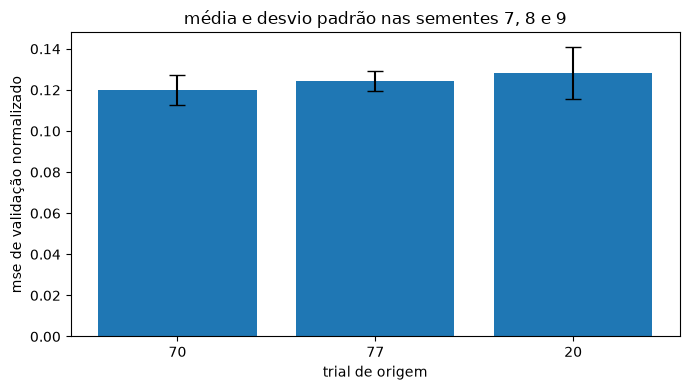

In [40]:
medias = resumo_confirmacao[("mse_val", "mean")]
desvios = resumo_confirmacao[("mse_val", "std")]

plt.figure(figsize=(7, 4))
plt.bar(medias.index.astype(str), medias.values, yerr=desvios.values, capsize=6)
plt.xlabel("trial de origem")
plt.ylabel("mse de validação normalizado")
plt.title("média e desvio padrão nas sementes 7, 8 e 9")
plt.tight_layout()
plt.show()

In [22]:
# trial 70 foi o vencedor, agora vamos testar um mse ponderado para dar mais peso ao peso, que esta com erros maiores

def criar_mse_ponderado(peso_loss):
    def mse_ponderado(y_real, y_hat):
        y_real = tf.cast(y_real, y_hat.dtype)
        erros_quadrados = tf.square(y_hat - y_real)

        # retorna uma loss por amostra, o keras calcula a média do batch
        return (erros_quadrados[:, 0] + peso_loss * erros_quadrados[:, 1]) / (1.0 + peso_loss)

    return mse_ponderado

In [34]:
def executar_experimento(config, learning_rate, seed=7, epochs=80, peso_loss=1.0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    modelo_exp = None
    inicio = perf_counter()

    try:
        modelo_exp = build_cnn(config)

        # mantém a loss original quando a ponderação é 1:1
        loss = "mse" if peso_loss == 1.0 else criar_mse_ponderado(peso_loss)
        modelo_exp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss=loss, metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

        callbacks_exp = [
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
            tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=0)
        ]

        historico_exp = modelo_exp.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=epochs, 
                                       batch_size=16, shuffle=True, callbacks=callbacks_exp, verbose=0)

        valores_val = np.asarray(historico_exp.history["val_mse_dados"])

        previsoes_norm = modelo_exp.predict(X_val, batch_size=16, verbose=0)
        previsoes = desnormaliza_rotulos(previsoes_norm)

        mae, rmse, r2 = avalia_predicao(y_val, previsoes)

        # objetivo sem a penalização l2, calculado nas duas saídas
        mse_val = np.mean((previsoes_norm.astype(np.float64) - y_val_norm) ** 2)

        return {
            "mse_val": float(mse_val),
            "mae_altura": float(mae[0]),
            "mae_peso": float(mae[1]),
            "rmse_altura": float(rmse[0]),
            "rmse_peso": float(rmse[1]),
            "r2_altura": float(r2[0]),
            "r2_peso": float(r2[1]),
            "parametros": int(modelo_exp.count_params()),
            "melhor_epoca": int(np.argmin(valores_val)) + 1,
            "epocas_executadas": len(valores_val),
            "tempo_segundos": float(perf_counter() - inicio),
            "historico": {
                nome: [float(v) for v in valores] for nome, valores in historico_exp.history.items()
            },
        }

    finally:
        del modelo_exp
        tf.keras.backend.clear_session()
        gc.collect()

In [42]:
trial_fixo = next(trial for trial in estudo_confirmacao.trials if trial.number == 70)

pasta_loss = Path("estudos") / "loss_ponderada_trial70"
pasta_loss.mkdir(parents=True, exist_ok=True)

resultados_loss = []

for seed in [7, 8, 9]:
    config = deepcopy(trial_fixo.user_attrs["config"])
    config["seed_augmentation"] = seed

    arquivo = pasta_loss / f"peso_2_seed_{seed}.json"

    if arquivo.exists():
        registro = json.loads(arquivo.read_text(encoding="utf-8"))
        print(f"carregado: loss 1:2, seed {seed}")

    else:
        print(f"treinando: loss 1:2, seed {seed}")

        resultado = executar_experimento(config=config, learning_rate=trial_fixo.params["learning_rate"], seed=seed, epochs=120, peso_loss=2.0)

        registro = {
            "trial_origem": 70,
            "seed": seed,
            "peso_loss": 2.0,
            "config": config,
            "learning_rate": trial_fixo.params["learning_rate"],
            "epochs_max": 120,
            **resultado,
        }

        temporario = arquivo.with_suffix(".tmp")
        temporario.write_text(json.dumps(registro, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
        temporario.replace(arquivo)

        print(f"mse sem ponderação: {registro['mse_val']:.4f}")

    resultados_loss.append(registro)

carregado: loss 1:2, seed 7
carregado: loss 1:2, seed 8
carregado: loss 1:2, seed 9


In [45]:
# resultados anteriores do mesmo trial, com a loss original
df_loss_original = df_confirmacao.loc[df_confirmacao["trial_origem"] == 70].copy()

df_loss_original["loss"] = "1:1"
df_loss_ponderada = pd.DataFrame([
    {
        "trial_origem": 70,
        "seed": resultado["seed"],
        "loss": "1:2",
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
    }
    for resultado in resultados_loss
])

comparacao_loss = pd.concat([df_loss_original, df_loss_ponderada], ignore_index=True)

In [45]:
comparacao_loss[["loss", "seed", *metricas_confirmacao]].sort_values(["seed", "loss"])

,loss,seed,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso,r2_altura,r2_peso
0,1:1,7,0.111653,2.521109,18.831819,3.108330,22.586558,0.748853,0.580922
3,1:2,7,0.117119,2.491389,18.182002,3.201088,22.928252,0.733640,0.568146
1,1:1,8,0.125006,2.620118,18.817755,3.371732,22.910069,0.704485,0.568831
4,1:2,8,0.100559,2.240880,18.559894,2.847601,22.566273,0.789219,0.581674
2,1:1,9,0.123437,2.481830,18.970052,3.272620,23.697903,0.721603,0.538667
5,1:2,9,0.114599,2.387710,17.153761,3.275772,21.337079,0.721067,0.626006


In [46]:
comparacao_loss.groupby("loss")[metricas_confirmacao].agg(["mean", "std"])

mse_val           mae_altura             mae_peso            \
          mean       std       mean       std       mean       std   
loss                                                                 
1:1   0.120032  0.007299   2.541019  0.071262  18.873208  0.084163   
1:2   0.110759  0.008923   2.373326  0.125873  17.965219  0.727701   

     rmse_altura            rmse_peso           r2_altura             r2_peso  \
            mean       std       mean       std      mean       std      mean   
loss                                                                            
1:1     3.250894  0.133038  23.064843  0.571610  0.724980  0.022376  0.562807   
1:2     3.108154  0.228714  22.277201  0.834044  0.747975  0.036267  0.591942   

                
           std  
loss            
1:1   0.021762  
1:2   0.030266

In [47]:
config_campeao = deepcopy(trial_fixo.user_attrs["config"])
modelo_contagem = build_cnn(config_campeao)

total_parametros = modelo_contagem.count_params()
limite_parametros = 5000000
margem_parametros = limite_parametros - total_parametros

print(f"parâmetros totais: {total_parametros:,}")
print(f"limite: {limite_parametros:,}")
print(f"margem disponível: {margem_parametros:,}")
print(f"uso do limite: {100 * total_parametros / limite_parametros:.2f}%")

del modelo_contagem

parâmetros totais: 3,887,202
limite: 5,000,000
margem disponível: 1,112,798
uso do limite: 77.74%


a arquitetura escolhida tem 3.887.202 parâmetros totais, aproximadamente 77,74% do limite permitido. resta uma margem de 1.112.798 parâmetros. vamos investigar, em uma busca restrita de 30 trials, se ampliar os canais ou redistribuir os blocos melhora o desempenho com a loss ponderada 1:2. a arquitetura atual será mantida como baseline, já que aumentar a capacidade não garante uma melhor generalização.

In [48]:
perfis_refinamento = {
    "referencia": {
        "canais": [48, 96, 160, 256],
        "blocos_por_estagio": [2, 2, 3, 2],
    },
    "mais_canais_finais": {
        "canais": [48, 96, 176, 272],
        "blocos_por_estagio": [2, 2, 3, 2],
    },
    "mais_canais_intermediarios": {
        "canais": [48, 112, 176, 256],
        "blocos_por_estagio": [2, 2, 3, 2],
    },
    "mais_bloco_estagio2": {
        "canais": [48, 96, 160, 256],
        "blocos_por_estagio": [2, 3, 3, 2],
    },
    "mais_bloco_estagio3": {
        "canais": [48, 96, 160, 256],
        "blocos_por_estagio": [2, 2, 4, 2],
    },
    "canais_e_bloco": {
        "canais": [48, 96, 176, 272],
        "blocos_por_estagio": [2, 2, 4, 2],
    },
}

config_base_refinamento = deepcopy(config_campeao)
config_base_refinamento.update({
    "cabeca": "conjunta",
    "unidades_dense": 64,
    "dropout": 0.4,
    "augmentation": False,
    "l2": 0.0,
    "usar_residual": True,
})

In [49]:
# filtar os perfis que passam do teto de parâmetros máximo (5 MI)

perfis_validos = {}
contagens = []

for nome, perfil in perfis_refinamento.items():
    modelo_contagem = None

    try:
        config = {
            **deepcopy(config_base_refinamento),
            **deepcopy(perfil),
        }

        modelo_contagem = build_cnn(config)
        parametros = modelo_contagem.count_params()

        valido = parametros <= 5000000

        if valido:
            perfis_validos[nome] = deepcopy(perfil)

        contagens.append({
            "perfil": nome,
            "parametros": parametros,
            "incluido": valido,
        })

    except LimiteParametrosError:
        contagens.append({
            "perfil": nome,
            "parametros": "acima de 5 milhões",
            "incluido": False,
        })

    finally:
        del modelo_contagem
        tf.keras.backend.clear_session()
        gc.collect()

pd.DataFrame(contagens)

,perfil,parametros,incluido
0,referencia,3887202,True
1,mais_canais_finais,4443490,True
2,mais_canais_intermediarios,4311906,True
3,mais_bloco_estagio2,4053858,True
4,mais_bloco_estagio3,4349282,True
5,canais_e_bloco,acima de 5 milhões,False


In [35]:
def objetivo_refinamento(trial):
    perfil = trial.suggest_categorical("perfil", list(perfis_validos))
    learning_rate = trial.suggest_float("learning_rate", 6e-4, 2e-3, log=True)

    config = {
        **deepcopy(config_base_refinamento),
        **deepcopy(perfis_validos[perfil]),
    }

    trial.set_user_attr("config", config)
    trial.set_user_attr("seed", 7)
    trial.set_user_attr("peso_loss", 2.0)
    trial.set_user_attr("epochs_max", 120)

    try:
        resultado = executar_experimento(config=config, learning_rate=learning_rate, seed=7, epochs=120, peso_loss=2.0)

    except tf.errors.ResourceExhaustedError:
        trial.set_user_attr("motivo_falha", "memória insuficiente")
        raise

    for nome, valor in resultado.items():
        trial.set_user_attr(nome, valor)

    return resultado["mse_val"]

In [36]:
# agora, criar o estudo e garantir uma comparação inicial de todos os perfis, colocando eles na fila de trials já

estudo_refinamento = optuna.create_study(study_name="cnn_refinamento_capacidade_v1", storage=storage, direction="minimize",
                                         sampler=optuna.samplers.TPESampler(seed=7, n_startup_trials=10,), pruner=optuna.pruners.NopPruner(), load_if_exists=True)

[I 2026-10-31 08:42:10,595] Using an existing study with name 'cnn_refinamento_capacidade_v1' instead of creating a new one.


In [ ]:
for perfil in perfis_validos:
    estudo_refinamento.enqueue_trial(
        {
            "perfil": perfil,
            "learning_rate": trial_fixo.params["learning_rate"],
        },
        skip_if_exists=True,
    )

In [52]:
def continuar_refinamento(meta_trials=30):
    finalizados = sum(trial.state.is_finished() for trial in estudo_refinamento.trials)
    restantes = max(0, meta_trials - finalizados)

    print("tentativas finalizadas:", finalizados)
    print("tentativas a executar:", restantes)

    if restantes:
        estudo_refinamento.optimize(objetivo_refinamento, n_trials=restantes, n_jobs=1, gc_after_trial=True,
                                    catch=(tf.errors.ResourceExhaustedError, FloatingPointError,), show_progress_bar=True)

In [47]:
continuar_refinamento(meta_trials=30)

tentativas finalizadas: 7
tentativas a executar: 23


  0%|          | 0/23 [00:00<?, ?it/s]2026-10-30 23:26:33.264852: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:26:33.879514: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:26:34.162786: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:26:34.410806: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=

[I 2026-10-30 23:32:50,903] Trial 8 finished with value: 0.12389208977809359 and parameters: {'perfil': 'mais_bloco_estagio3', 'learning_rate': 0.0011474117566239589}. Best is trial 1 with value: 0.10875199565212817.


Best trial: 1. Best value: 0.108752:   4%|▍         | 1/23 [06:18<2:18:54, 378.83s/it]2026-10-30 23:32:51.995819: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:32:52.513432: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 364118016 exceeds 10% of free system memory.
2026-10-30 23:33:10.166276: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  t

[I 2026-10-30 23:38:27,382] Trial 9 finished with value: 0.12454018847460294 and parameters: {'perfil': 'mais_bloco_estagio3', 'learning_rate': 0.001579098820394358}. Best is trial 1 with value: 0.10875199565212817.


Best trial: 1. Best value: 0.108752:   9%|▊         | 2/23 [11:55<2:03:52, 353.94s/it]2026-10-30 23:38:46.866811: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-30 23:45:12.985788: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset

... (39 outputs left out)

[I 2026-10-31 01:44:27,258] Trial 29 finished with value: 0.14691431061511262 and parameters: {'perfil': 'mais_canais_intermediarios', 'learning_rate': 0.001970328016951698}. Best is trial 28 with value: 0.10335134258603942.


Best trial: 28. Best value: 0.103351:  96%|█████████▌| 22/23 [2:17:56<06:47, 407.77s/it]2026-10-31 01:44:31.493317: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 01:44:47.820651: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_datas

[I 2026-10-31 01:51:32,051] Trial 30 finished with value: 0.11340868877514142 and parameters: {'perfil': 'referencia', 'learning_rate': 0.001271712475050212}. Best is trial 28 with value: 0.10335134258603942.


Best trial: 28. Best value: 0.103351: 100%|██████████| 23/23 [2:25:01<00:00, 378.31s/it]


In [37]:
resultados_refinamento = tabela_estudo(estudo_refinamento)
resultados_refinamento

,trial,mse_val,perfil,learning_rate,epocas_executadas,epochs_max,mae_altura,mae_peso,melhor_epoca,parametros,peso_loss,r2_altura,r2_peso,rmse_altura,rmse_peso,seed,tempo_segundos
0,28,0.103351,referencia,0.001097,49,120,2.330869,18.660176,34,3887202,2.0,0.772940,0.597721,2.955519,22.129221,7,336.648090
1,1,0.108752,mais_canais_finais,0.001236,58,120,2.499428,17.795593,43,4443490,2.0,0.739051,0.635130,3.168410,21.075213,7,210.156344
2,22,0.112160,mais_canais_finais,0.001254,36,120,2.649091,17.669067,21,4443490,2.0,0.739524,0.600747,3.165537,22.045854,7,264.108776
3,30,0.113409,referencia,0.001272,62,120,2.513322,17.404411,47,3887202,2.0,0.736949,0.595439,3.181146,22.191906,7,419.434881
4,18,0.116231,referencia,0.001027,36,120,2.298048,21.895685,21,3887202,2.0,0.801433,0.396931,2.763866,27.094817,7,249.900080
5,23,0.116846,mais_canais_finais,0.001236,53,120,2.584986,18.384211,38,4443490,2.0,0.733353,0.571568,3.202812,22.837242,7,372.395717
6,0,0.117119,referencia,0.001236,85,120,2.491389,18.182002,70,3887202,2.0,0.733640,0.568146,3.201088,22.928252,7,294.178756
7,10,0.118795,mais_bloco_estagio2,0.001034,56,120,2.272930,18.589973,41,4053858,2.0,0.754268,0.497132,3.074639,24.741696,7,406.157153
8,16,0.120981,mais_canais_finais,0.001029,78,120,2.671021,19.002213,63,4443490,2.0,0.718267,0.571389,3.292170,22.842004,7,553.584984
9,2,0.121934,mais_canais_intermediarios,0.001236,62,120,2.514674,18.142970,47,4311906,2.0,0.713403,0.575035,3.320466,22.744636,7,228.736758


In [38]:
melhores_por_perfil = resultados_refinamento.sort_values("mse_val").drop_duplicates("perfil")

melhores_por_perfil[[
    "trial",
    "perfil",
    "parametros",
    "learning_rate",
    "mse_val",
    "mae_altura",
    "mae_peso",
    "rmse_altura",
    "rmse_peso",
]]

,trial,perfil,parametros,learning_rate,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso
0,28,referencia,3887202,0.001097,0.103351,2.330869,18.660176,2.955519,22.129221
1,1,mais_canais_finais,4443490,0.001236,0.108752,2.499428,17.795593,3.168410,21.075213
7,10,mais_bloco_estagio2,4053858,0.001034,0.118795,2.272930,18.589973,3.074639,24.741696
9,2,mais_canais_intermediarios,4311906,0.001236,0.121934,2.514674,18.142970,3.320466,22.744636
13,5,mais_bloco_estagio3,4349282,0.001147,0.123743,2.469926,19.663101,3.280365,23.684435


In [39]:
estudo_final = optuna.load_study(study_name="cnn_refinamento_capacidade_v1", storage=storage)

top2_final = sorted(estudo_final.get_trials(states=(optuna.trial.TrialState.COMPLETE,)), key=lambda trial: trial.value)[:2]

print("trials selecionados:", [trial.number for trial in top2_final])

trials selecionados: [28, 1]


In [40]:
pasta_final = Path("estudos") / "confirmacao_refinamento"
pasta_final.mkdir(parents=True, exist_ok=True)

resultados_confirmacao_final = []

for trial in top2_final:
    for seed in [7, 8, 9]:
        arquivo = pasta_final / f"trial_{trial.number}_seed_{seed}.json"

        if arquivo.exists():
            registro = json.loads(arquivo.read_text(encoding="utf-8"))
            print(f"carregado: trial {trial.number}, seed {seed}")

        else:
            config = deepcopy(trial.user_attrs["config"])
            config["seed_augmentation"] = seed

            print(f"treinando: trial {trial.number}, seed {seed}")

            resultado = executar_experimento(config=config, learning_rate=trial.params["learning_rate"], seed=seed, epochs=120, peso_loss=2.0)

            registro = {
                "estudo_origem": estudo_final.study_name,
                "trial_origem": trial.number,
                "seed": seed,
                "config": config,
                "learning_rate": trial.params["learning_rate"],
                "peso_loss": 2.0,
                "epochs_max": 120,
                **resultado,
            }

            temporario = arquivo.with_suffix(".tmp")
            temporario.write_text(json.dumps(registro, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
            temporario.replace(arquivo)

        resultados_confirmacao_final.append(registro)

treinando: trial 28, seed 7


I0000 00:00:1793446947.203098    6432 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4177 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
2026-10-31 08:42:28.519472: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:42:34.617338: I external/local

treinando: trial 28, seed 8


2026-10-31 08:44:37.390626: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:47:18.735468: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

treinando: trial 28, seed 9


2026-10-31 08:47:29.220373: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:49:40.569276: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

... (2 outputs left out)

treinando: trial 1, seed 8


2026-10-31 08:53:21.787284: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:55:53.821270: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

treinando: trial 1, seed 9


2026-10-31 08:56:04.886291: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 08:57:41.470134: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

In [46]:
linhas = []

for resultado in resultados_loss:
    linhas.append({
        "candidato": "trial 70 original, loss 1:2",
        "seed": resultado["seed"],
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
    })

for resultado in resultados_confirmacao_final:
    linhas.append({
        "candidato": f"refinamento trial {resultado['trial_origem']}",
        "seed": resultado["seed"],
        **{
            metrica: resultado[metrica]
            for metrica in metricas_confirmacao
        },
    })

In [47]:
df_confirmacao_final = pd.DataFrame(linhas)

df_confirmacao_final.sort_values(["candidato", "seed"])

,candidato,seed,mse_val,mae_altura,mae_peso,rmse_altura,rmse_peso,r2_altura,r2_peso
6,refinamento trial 1,7,0.108752,2.499428,17.795593,3.168410,21.075213,0.739051,0.635130
7,refinamento trial 1,8,0.116528,2.422595,18.735321,3.131566,23.572700,0.745084,0.543529
8,refinamento trial 1,9,0.132212,2.730800,18.800250,3.294414,25.561984,0.717883,0.463235
3,refinamento trial 28,7,0.121818,2.610884,19.041405,3.213023,23.976621,0.731650,0.527751
4,refinamento trial 28,8,0.122365,2.505830,17.408862,3.415716,21.646352,0.696725,0.615086
5,refinamento trial 28,9,0.118657,2.528682,19.623214,3.133456,24.080312,0.744777,0.523658
0,"trial 70 original, loss 1:2",7,0.117119,2.491389,18.182002,3.201088,22.928252,0.733640,0.568146
1,"trial 70 original, loss 1:2",8,0.100559,2.240880,18.559894,2.847601,22.566273,0.789219,0.581674
2,"trial 70 original, loss 1:2",9,0.114599,2.387710,17.153761,3.275772,21.337079,0.721067,0.626006


In [48]:
resumo_final = (
    df_confirmacao_final
    .groupby("candidato")[metricas_confirmacao]
    .agg(["mean", "std"])
    .sort_values(("mse_val", "mean"))
)

resumo_final

mse_val           mae_altura            \
                                 mean       std       mean       std   
candidato                                                              
trial 70 original, loss 1:2  0.110759  0.008923   2.373326  0.125873   
refinamento trial 1          0.119164  0.011950   2.550941  0.160430   
refinamento trial 28         0.120947  0.002002   2.548465  0.055251   

                              mae_peso           rmse_altura            \
                                  mean       std        mean       std   
candidato                                                                
trial 70 original, loss 1:2  17.965219  0.727701    3.108154  0.228714   
refinamento trial 1          18.443721  0.562234    3.198130  0.085395   
refinamento trial 28         18.691160  1.147973    3.254065  0.145537   

                             rmse_peso           r2_altura            \
                                  mean       std      mean       std   
candidato                                                              
trial 70 original, loss 1:2  22.277201  0.834044  0.747975  0.036267   
refinamento trial 1          23.403299  2.248177  0.734006  0.014285   
refinamento trial 28         23.234428  1.376291  0.724384  0.024836   

                              r2_peso            
                                 mean       std  
candidato                                        
trial 70 original, loss 1:2  0.591942  0.030266  
refinamento trial 1          0.547298  0.086009  
refinamento trial 28         0.555498  0.051645

### Escolha final da CNN

depois da busca e da comparação nas sementes 7, 8 e 9, escolhemos a configuração original do trial 70, do estudo da fase 2, com a loss ponderada 1:2 para altura e peso. ela apresentou o menor MSE médio de validação sem ponderação, de aproximadamente 0,1108, e os menores erros médios nas duas tarefas: MAE de 2,37 cm para altura e 17,97 kg para peso. os valores médios de RMSE foram 3,11 cm e 22,28 kg, respectivamente.

a última busca investigou se ampliar os canais ou acrescentar blocos, aproveitando a margem até 5 milhões de parâmetros, melhoraria os resultados. na confirmação, a alternativa maior teve MSE médio de 0,1192, enquanto a arquitetura original com outro learning rate teve 0,1209. assim, nas configurações e sementes avaliadas, o refinamento não trouxe melhora no desempenho médio. mantemos a configuração anterior e encerramos a busca da CNN própria.

o modelo escolhido possui 3.887.202 parâmetros totais, canais [48, 96, 160, 256] e [2, 2, 3, 2] blocos residuais por estágio. utiliza global average pooling, cabeça conjunta com 64 unidades, dropout de 0,4 e learning rate inicial de aproximadamente 0,001236, sem augmentation ou l2 nessa configuração final. o treinamento usa os rótulos padronizados e dá o dobro da contribuição relativa ao erro quadrático do peso.

vamos fixar a semente 7 para a execução final, preservar os melhores pesos e conferir as previsões após salvar e recarregar o modelo. depois apresentaremos as curvas, as métricas e os gráficos de erros dessa execução, além de preparar a inferência no conjunto de teste e a exportação das previsões em csv.

### Treinamento do modelo final

In [49]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(7)

config_final = deepcopy(trial_fixo.user_attrs["config"])
config_final["seed_augmentation"] = 7

learning_rate_final = trial_fixo.params["learning_rate"]

modelo_final = build_cnn(config_final)

modelo_final.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate_final), loss=criar_mse_ponderado(2.0), metrics=[tf.keras.metrics.MeanSquaredError(name="mse_dados")])

modelo_final.summary()

Model: "cnn_residual_conjunta"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagem (InputLayer) │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_inicial        │ (None, 128, 128,  │        864 │ imagem[0][0]      │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv_inicial[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │     13,824 │ re_lu[0][0]       │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     20,736 │ re_lu_1[0][0]     │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      1,536 │ re_lu[0][0]       │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 48)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ add[0][0]         │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     20,736 │ re_lu_2[0][0]     │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     20,736 │ re_lu_3[0][0]   

 Total params: 3,887,202 (14.83 MB)

 Trainable params: 3,880,898 (14.80 MB)

 Non-trainable params: 6,304 (24.62 KB)

In [50]:
callbacks_final = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1)
]

inicio_final = perf_counter()

historico_final = modelo_final.fit(X_train, y_train_norm, validation_data=(X_val, y_val_norm), epochs=120, batch_size=16,
                                   shuffle=True, callbacks=callbacks_final, verbose=2)

tempo_final = perf_counter() - inicio_final

melhor_epoca_final = (int(np.argmin(historico_final.history["val_mse_dados"])) + 1)
print("melhor época:", melhor_epoca_final)
print(f"tempo total: {tempo_final / 60:.2f} min")

Epoch 1/120


2026-10-31 09:19:22.584453: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
2026-10-31 09:19:31.567398: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

29/29 - 10s - 328ms/step - loss: 1.3266 - mse_dados: 1.2883 - val_loss: 3029.4846 - val_mse_dados: 4303.2324 - learning_rate: 0.0012
Epoch 2/120
29/29 - 3s - 117ms/step - loss: 0.6641 - mse_dados: 0.6615 - val_loss: 131.6581 - val_mse_dados: 168.1327 - learning_rate: 0.0012
Epoch 3/120
29/29 - 3s - 118ms/step - loss: 0.4221 - mse_dados: 0.4356 - val_loss: 0.9734 - val_mse_dados: 1.1359 - learning_rate: 0.0012
Epoch 4/120
29/29 - 3s - 117ms/step - loss: 0.3648 - mse_dados: 0.4019 - val_loss: 0.3796 - val_mse_dados: 0.3947 - learning_rate: 0.0012
Epoch 5/120
29/29 - 3s - 116ms/step - loss: 0.2994 - mse_dados: 0.3215 - val_loss: 0.7977 - val_mse_dados: 1.0058 - learning_rate: 0.0012
Epoch 6/120
29/29 - 3s - 117ms/step - loss: 0.3022 - mse_dados: 0.3290 - val_loss: 0.2474 - val_mse_dados: 0.2949 - learning_rate: 0.0012
Epoch 7/120
29/29 - 3s - 117ms/step - loss: 0.2487 - mse_dados: 0.2752 - val_loss: 0.3404 - val_mse_dados: 0.3183 - learning_rate: 0.0012
Epoch 8/120
29/29 - 3s - 117ms/step

### Exportar o modelo com o pré e pós processamento junto

In [54]:
# reconstrói a mesma arquitetura sem compilar e copia os pesos treinados
rede_inferencia = build_cnn(config_final)
rede_inferencia.set_weights(modelo_final.get_weights())

entrada_exportacao = tf.keras.Input(shape=(256, 256, 3), dtype="float32", name="imagem_pixels_0_255")
x = layers.Rescaling(1.0 / 255.0, name="normalizacao_pixels")(entrada_exportacao)

predicoes_norm = rede_inferencia(x)
predicoes_unidades = layers.Normalization(axis=-1, mean=media_y.tolist(), variance=(desvio_y ** 2).tolist(), invert=True, name="altura_cm_peso_kg")(predicoes_norm)

modelo_exportacao = tf.keras.Model(entrada_exportacao, predicoes_unidades, name="cnn_bovinos")
modelo_exportacao.summary()

Model: "cnn_bovinos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem_pixels_0_255             │ (None, 256, 256, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao_pixels (Rescaling) │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_residual_conjunta           │ (None, 2)              │     3,887,202 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ altura_cm_peso_kg               │ (None, 2)              │             0 │
│ (Normalization)                 │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,887,202 (14.83 MB)

 Trainable params: 3,880,898 (14.80 MB)

 Non-trainable params: 6,304 (24.62 KB)

In [ ]:
# lê os pixels originais, pois o modelo exportado normaliza internamente
X_val_pixels = np.stack([io.imread(caminho) for caminho in df_val["caminho"]]).astype(np.float32)

# previsões do modelo final treinado
previsoes_final_norm = modelo_final.predict(X_val, batch_size=16, verbose=0)
previsoes_final = desnormaliza_rotulos(previsoes_final_norm)

# previsões do modelo final exportado
previsoes_exportacao = modelo_exportacao.predict(X_val_pixels, batch_size=16, verbose=0)

np.testing.assert_allclose(previsoes_final, previsoes_exportacao, atol=1e-2)

### Salvar o modelo, carregar e conferir de novo

In [ ]:
pasta_modelo = Path("modelos")
pasta_modelo.mkdir(exist_ok=True)

caminho_modelo = pasta_modelo / "cnn_bovinos_final.keras"

modelo_exportacao.save(caminho_modelo)

modelo_carregado = tf.keras.models.load_model(caminho_modelo, compile=False)

previsoes_carregadas = modelo_carregado.predict(X_val_pixels, batch_size=16, verbose=0)

np.testing.assert_allclose(previsoes_exportacao, previsoes_carregadas, atol=1e-3)

print("maior diferença após carregar:", np.max(np.abs(previsoes_exportacao - previsoes_carregadas)))

In [41]:
# so carregar o modelo
pasta_modelo = Path("modelos")
pasta_modelo.mkdir(exist_ok=True)

caminho_modelo = pasta_modelo / "cnn_bovinos_final.keras"

modelo_carregado = tf.keras.models.load_model(caminho_modelo, compile=False)

previsoes_carregadas = modelo_carregado.predict(X_val_pixels, batch_size=16, verbose=0)

### Métricas e curvas do modelo salvo

In [42]:
mae_final, rmse_final, r2_final = avalia_predicao(y_val, previsoes_carregadas)

metricas_final = pd.DataFrame({
    "variável": ["altura", "peso"],
    "unidade": ["cm", "kg"],
    "mae": mae_final,
    "rmse": rmse_final,
    "r2": r2_final,
})

metricas_final

,variável,unidade,mae,rmse,r2
0,altura,cm,2.491505,3.201117,0.733635
1,peso,kg,18.181645,22.927066,0.568191


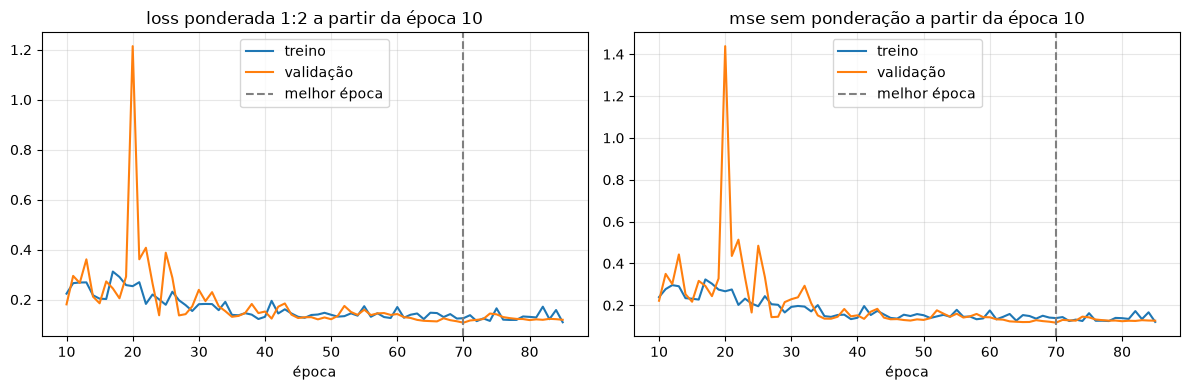

In [63]:
epocas_final = np.arange(1, len(historico_final.history["loss"]) + 1)

# recorta os dados para a escala vertical não ficar muito esticada
epoca_inicio = 10
recorte = slice(epoca_inicio - 1, None)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

for eixo, chave, titulo in [(eixos[0], "loss", "loss ponderada 1:2"), (eixos[1], "mse_dados", "mse sem ponderação")]:
    eixo.plot(epocas_final[recorte], historico_final.history[chave][recorte], label="treino")
    eixo.plot(epocas_final[recorte],historico_final.history[f"val_{chave}"][recorte], label="validação")
    eixo.axvline(melhor_epoca_final, color="gray", linestyle="--", label="melhor época")
    eixo.set_title(f"{titulo} a partir da época {epoca_inicio}")
    eixo.set_xlabel("época")
    eixo.legend()
    eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Análise das previsões do modelo final no conjunto de validação

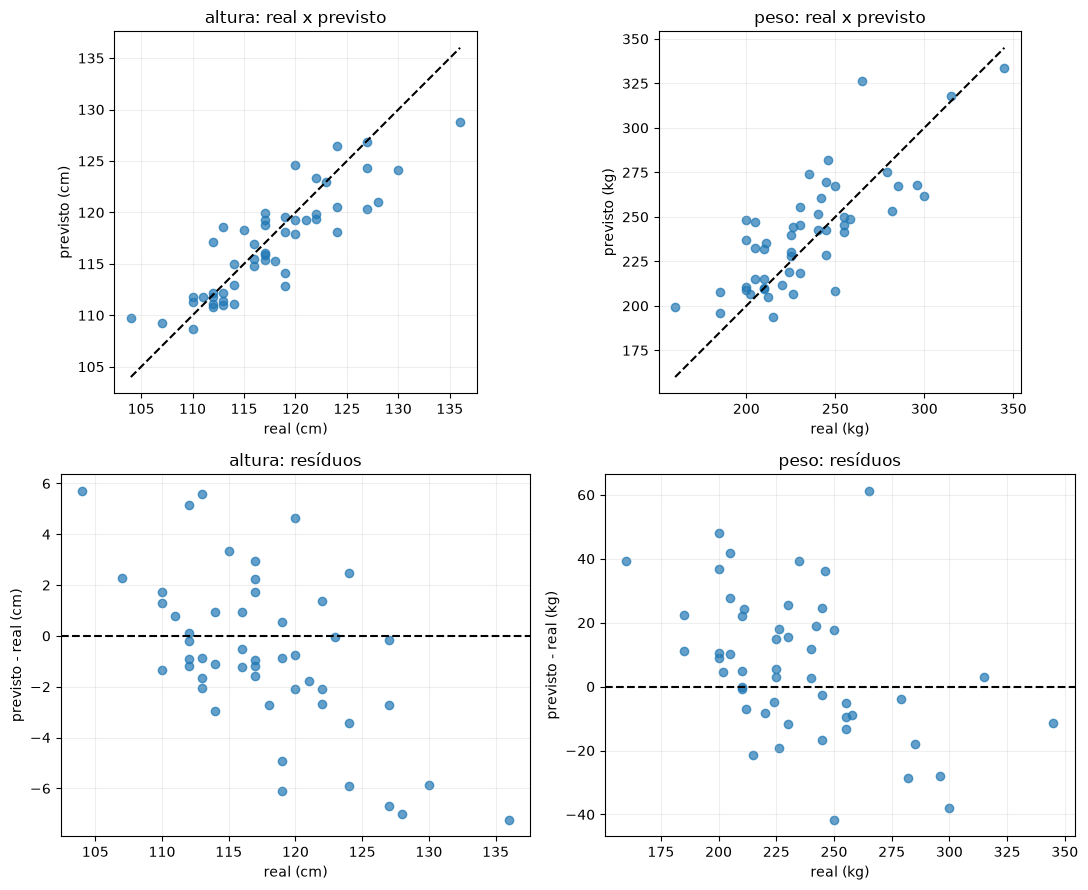

In [64]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 9))

for coluna, nome, unidade in [(0, "altura", "cm"), (1, "peso", "kg")]:
    real = y_val[:, coluna]
    previsto = previsoes_carregadas[:, coluna]
    residuos = previsto - real

    minimo = min(real.min(), previsto.min())
    maximo = max(real.max(), previsto.max())

    eixos[0, coluna].scatter(real, previsto, alpha=0.7)
    eixos[0, coluna].plot([minimo, maximo], [minimo, maximo], "--", color="black")
    eixos[0, coluna].set(title=f"{nome}: real x previsto", xlabel=f"real ({unidade})", ylabel=f"previsto ({unidade})")
    eixos[0, coluna].set_aspect("equal", adjustable="box")

    eixos[1, coluna].scatter(real, residuos, alpha=0.7)
    eixos[1, coluna].axhline(0, color="black", linestyle="--")
    eixos[1, coluna].set(title=f"{nome}: resíduos", xlabel=f"real ({unidade})", ylabel=f"previsto - real ({unidade})")

for eixo in eixos.flat:
    eixo.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [65]:
analise_final = df_val[["id", "caminho", "altura_cm", "peso_kg"]].copy()

analise_final["altura_prevista_cm"] = previsoes_carregadas[:, 0]
analise_final["peso_previsto_kg"] = previsoes_carregadas[:, 1]

analise_final["erro_altura_cm"] = (analise_final["altura_prevista_cm"] - analise_final["altura_cm"])
analise_final["erro_peso_kg"] = (analise_final["peso_previsto_kg"] - analise_final["peso_kg"])

analise_final.drop(columns="caminho")

,id,altura_cm,peso_kg,altura_prevista_cm,peso_previsto_kg,erro_altura_cm,erro_peso_kg
0,001,123.0,279.0,122.947693,275.098206,-0.052307,-3.901794
1,002,130.0,296.0,124.132385,268.042542,-5.867615,-27.957458
2,003,112.0,212.0,110.833061,204.848938,-1.166939,-7.151062
3,004,110.0,202.0,111.282967,206.607101,1.282967,4.607101
4,005,114.0,205.0,112.901634,215.194916,-1.098366,10.194916
5,006,122.0,258.0,119.893303,248.977280,-2.106697,-9.022720
6,007,117.0,240.0,119.936806,251.627518,2.936806,11.627518
7,008,110.0,215.0,108.658501,193.677048,-1.341499,-21.322952
8,009,114.0,226.0,111.060295,206.720856,-2.939705,-19.279144
9,010,119.0,224.0,114.075050,219.279449,-4.924950,-4.720551


In [67]:
print("erro médio com sinal [altura, peso]:\n", analise_final[["erro_altura_cm", "erro_peso_kg"]].mean())

erro médio com sinal [altura, peso]:
 erro_altura_cm   -0.741307
erro_peso_kg      6.231882
dtype: float64


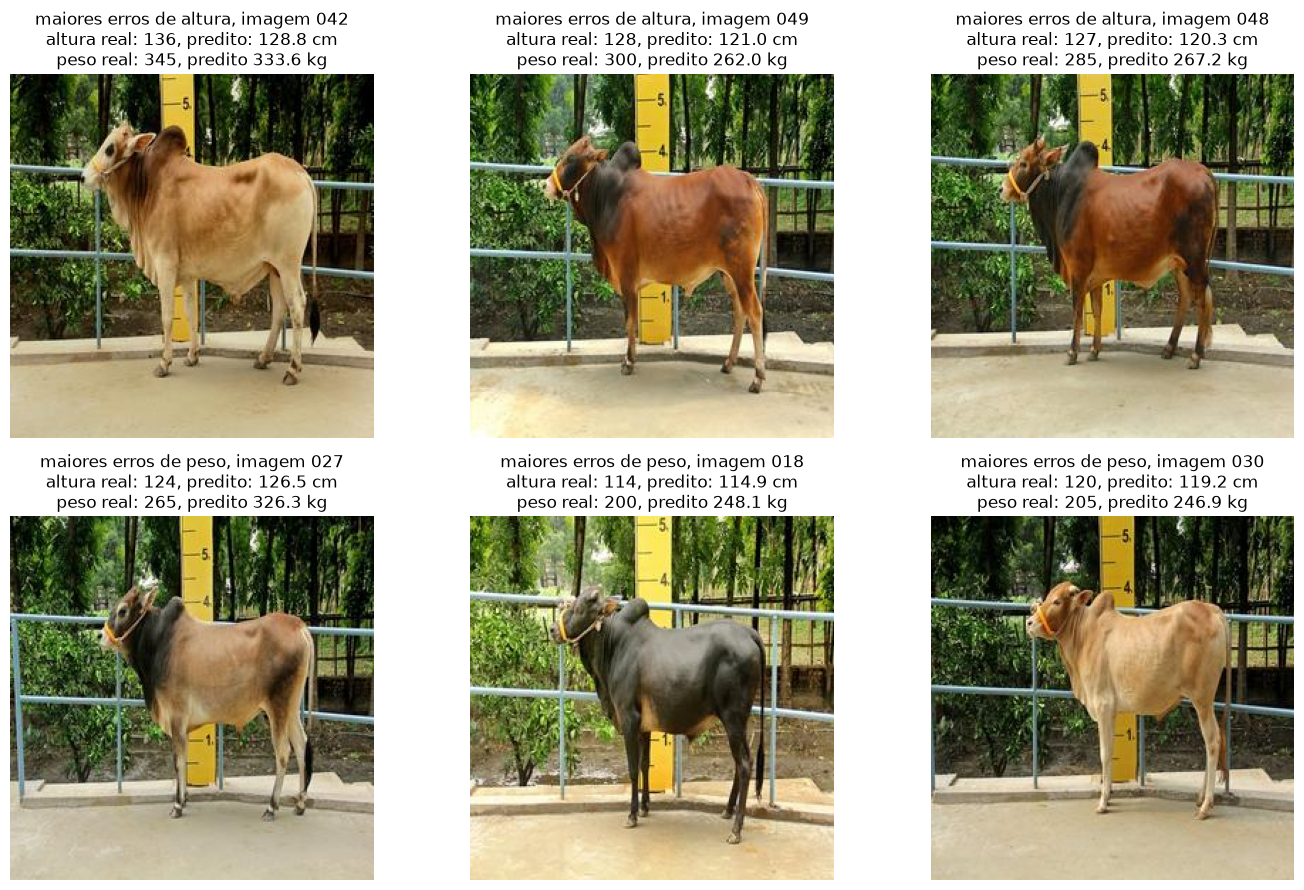

In [70]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 9))

for linha, coluna_erro, titulo in [(0, "erro_altura_cm", "maiores erros de altura"), (1, "erro_peso_kg", "maiores erros de peso")]:
    indices = analise_final[coluna_erro].abs().nlargest(3).index

    for eixo, indice in zip(eixos[linha], indices):
        amostra = analise_final.loc[indice]

        eixo.imshow(io.imread(amostra["caminho"]))
        eixo.set_title(
            f"{titulo}, imagem {amostra['id']}\n"
            f"altura real: {amostra['altura_cm']:.0f}, predito: "
            f"{amostra['altura_prevista_cm']:.1f} cm\n"
            f"peso real: {amostra['peso_kg']:.0f}, predito "
            f"{amostra['peso_previsto_kg']:.1f} kg"
        )
        eixo.axis("off")

plt.tight_layout()
plt.show()

### Testando usar Transfer Learning para melhorar as predições, usando o MobileNetv4-conv-small como backbone

In [26]:
import sys
import tensorflow as tf
import keras

print("python:", sys.version)
print("tensorflow:", tf.__version__)
print("keras:", keras.__version__)
print("backend:", keras.backend.backend())

python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
tensorflow: 2.20.0
keras: 3.15.0
backend: tensorflow


In [27]:
# %pip install zeromodels

In [28]:
import importlib
import importlib.metadata
import inspect
import pkgutil
import zeromodels.models

print("zeromodels:", importlib.metadata.version("zeromodels"))

modulos_v4 = [modulo.name for modulo in pkgutil.iter_modules(zeromodels.models.__path__) if "mobilenet" in modulo.name.lower() and "4" in modulo.name]
print("módulos da mobilenetv4:", modulos_v4)

for nome in modulos_v4:
    modulo = importlib.import_module(f"zeromodels.models.{nome}")

    for nome_classe, classe in inspect.getmembers(modulo, inspect.isclass):
        if "mobilenet" in nome_classe.lower():
            print("\nclasse:", nome_classe)
            print("construtor:", inspect.signature(classe))

            if hasattr(classe, "from_weights"):
                print("from_weights:", inspect.signature(classe.from_weights))

zeromodels: 1.3.6
módulos da mobilenetv4: ['mobilenetv4']

classe: MobileNetV4Config
construtor: (**kwargs)

classe: MobileNetV4ImageClassify
construtor: (*args, **kwargs)
from_weights: (identifier, load_weights=True, skip_mismatch=False, attn_implementation=None, quantization=None, load_dtype=None, cache_converted=False, **kwargs)

classe: MobileNetV4ImageProcessor
construtor: (size=None, crop_size=None, resample=None, do_resize=True, do_center_crop=None, do_rescale=True, rescale_factor=0.00392156862745098, do_normalize=True, image_mean=None, image_std=None, antialias=True, return_tensor=True, data_format=None, **kwargs)
from_weights: (identifier, **kwargs)

classe: MobileNetV4Model
construtor: (*args, **kwargs)
from_weights: (identifier, load_weights=True, skip_mismatch=False, attn_implementation=None, quantization=None, load_dtype=None, cache_converted=False, **kwargs)


In [29]:
# carregar agora o backbone e o pré-processador
from zeromodels.models.mobilenetv4 import MobileNetV4Model, MobileNetV4ImageProcessor

checkpoint_v4 = ("zeromodels/mobilenetv4_conv_small_e2400_r224_in1k")
backbone_v4 = MobileNetV4Model.from_weights(checkpoint_v4)
processor_v4 = MobileNetV4ImageProcessor.from_weights(checkpoint_v4)

print("variante:", backbone_v4.arch)
print("entrada:", backbone_v4.input_shape)
print("saída:", backbone_v4.output_shape)
print("parâmetros do backbone:", backbone_v4.count_params())

variante: conv_small
entrada: (None, 224, 224, 3)
saída: (None, 7, 7, 960)
parâmetros do backbone: 1284192


In [30]:
from PIL import Image

imagem_exemplo = Image.open(df_val.iloc[0]["caminho"]).convert("RGB")

pixels_v4 = processor_v4(imagem_exemplo)
features_v4 = backbone_v4(pixels_v4, training=False)

print("imagem processada:", pixels_v4.shape)
print("características:", features_v4.shape)

imagem processada: (1, 224, 224, 3)
características: (1, 7, 7, 960)


agora, vamos usar o backbone congelado e somente ajustar a nova cabeça para regressão da [altura, peso]

In [31]:
keras.utils.set_random_seed(7)

backbone_v4.trainable = False

entrada_v4 = keras.Input(shape=backbone_v4.input_shape[1:], name="imagem_processada")

# mantém o backbone em modo de inferência, incluindo o batch normalization
x = backbone_v4(entrada_v4, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(64, activation="relu")(x)
x = keras.layers.Dropout(0.2)(x)
saida_v4 = keras.layers.Dense(2, name="altura_peso_norm")(x)

modelo_v4 = keras.Model(entrada_v4, saida_v4, name="regressao_mobilenetv4")

print("parâmetros totais:", modelo_v4.count_params())

modelo_v4.summary()

parâmetros totais: 1345826


Model: "regressao_mobilenetv4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem_processada (InputLayer)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV4Model                │ (None, 7, 7, 960)      │     1,284,192 │
│ (MobileNetV4Model)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        61,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ altura_peso_norm (Dense)        │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,345,826 (5.13 MB)

 Trainable params: 61,634 (240.76 KB)

 Non-trainable params: 1,284,192 (4.90 MB)

In [32]:
processor_v4 = MobileNetV4ImageProcessor.from_weights(checkpoint_v4, size={"height": 224, "width": 224}, do_center_crop=False)

print("tamanho:", processor_v4.size)
print("média dos canais:", processor_v4.image_mean)
print("desvio dos canais:", processor_v4.image_std)

tamanho: {'height': 224, 'width': 224}
média dos canais: (0.485, 0.456, 0.406)
desvio dos canais: (0.229, 0.224, 0.225)


In [33]:
def preparar_imagens_v4(tabela):
    imagens = []

    for caminho in tabela["caminho"]:
        imagem = io.imread(caminho)
        processada = processor_v4(imagem)

        imagens.append(keras.ops.convert_to_numpy(processada)[0])

    return np.stack(imagens).astype(np.float32)


X_train_v4 = preparar_imagens_v4(df_treino)
X_val_v4 = preparar_imagens_v4(df_val)

print("treino:", X_train_v4.shape)
print("validação:", X_val_v4.shape)

treino: (463, 224, 224, 3)
validação: (50, 224, 224, 3)


In [34]:
modelo_v4.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=criar_mse_ponderado(2.0), metrics=[keras.metrics.MeanSquaredError(name="mse_dados")])

callbacks_cabeca_v4 = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1)
]

inicio_cabeca_v4 = perf_counter()

historico_cabeca_v4 = modelo_v4.fit(X_train_v4, y_train_norm, validation_data=(X_val_v4, y_val_norm), epochs=120,
                                    batch_size=16, shuffle=True, callbacks=callbacks_cabeca_v4, verbose=2)

tempo_cabeca_v4 = perf_counter() - inicio_cabeca_v4

print(f"tempo: {tempo_cabeca_v4 / 60:.2f} min")
print("melhor época:", np.argmin(historico_cabeca_v4.history["val_mse_dados"]) + 1)

Epoch 1/120
29/29 - 9s - 305ms/step - loss: 0.9750 - mse_dados: 0.9836 - val_loss: 0.3262 - val_mse_dados: 0.3789 - learning_rate: 0.0010
Epoch 2/120
29/29 - 0s - 16ms/step - loss: 0.8736 - mse_dados: 0.8933 - val_loss: 0.3132 - val_mse_dados: 0.3592 - learning_rate: 0.0010
Epoch 3/120
29/29 - 0s - 15ms/step - loss: 0.7641 - mse_dados: 0.7913 - val_loss: 0.3013 - val_mse_dados: 0.3411 - learning_rate: 0.0010
Epoch 4/120
29/29 - 0s - 15ms/step - loss: 0.6615 - mse_dados: 0.6914 - val_loss: 0.2946 - val_mse_dados: 0.3273 - learning_rate: 0.0010
Epoch 5/120
29/29 - 0s - 15ms/step - loss: 0.5673 - mse_dados: 0.5970 - val_loss: 0.3003 - val_mse_dados: 0.3236 - learning_rate: 0.0010
Epoch 6/120
29/29 - 0s - 16ms/step - loss: 0.4802 - mse_dados: 0.5093 - val_loss: 0.2795 - val_mse_dados: 0.3003 - learning_rate: 0.0010
Epoch 7/120
29/29 - 0s - 15ms/step - loss: 0.4272 - mse_dados: 0.4513 - val_loss: 0.2495 - val_mse_dados: 0.2704 - learning_rate: 0.0010
Epoch 8/120
29/29 - 0s - 15ms/step - los

In [44]:
previsoes_cabeca_v4_norm = modelo_v4.predict(X_val_v4, batch_size=16, verbose=0)

previsoes_cabeca_v4 = desnormaliza_rotulos(previsoes_cabeca_v4_norm)

mae_v4, rmse_v4, r2_v4 = avalia_predicao(y_val, previsoes_cabeca_v4)

metricas_cabeca_v4 = pd.DataFrame({
    "variável": ["altura", "peso"],
    "unidade": ["cm", "kg"],
    "mae": mae_v4,
    "rmse": rmse_v4,
    "r2": r2_v4,
})

comparacao_tl = pd.concat([
    metricas_final.assign(modelo="cnn própria"),
    metricas_cabeca_v4.assign(modelo="v4, mas só ajustando cabeça"),
], ignore_index=True)

comparacao_tl

,variável,unidade,mae,rmse,r2,modelo
0,altura,cm,2.491505,3.201117,0.733635,cnn própria
1,peso,kg,18.181645,22.927066,0.568191,cnn própria
2,altura,cm,2.578786,3.265929,0.722740,"v4, mas só ajustando cabeça"
3,peso,kg,19.254586,24.780391,0.495558,"v4, mas só ajustando cabeça"


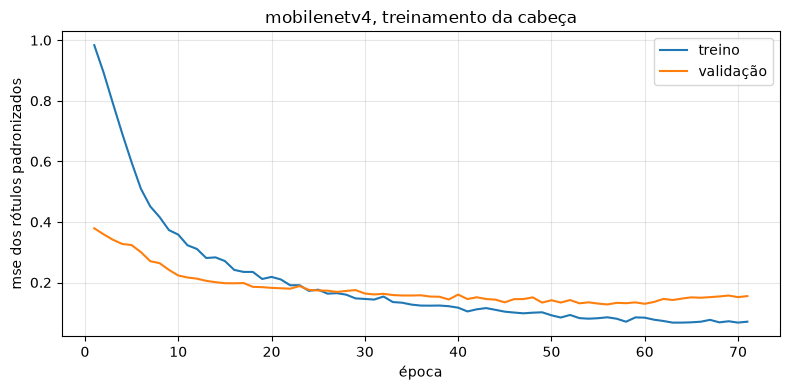

In [45]:
epocas_cabeca_v4 = np.arange(1, len(historico_cabeca_v4.history["mse_dados"]) + 1)

plt.figure(figsize=(8, 4))

plt.plot(epocas_cabeca_v4, historico_cabeca_v4.history["mse_dados"], label="treino")
plt.plot(epocas_cabeca_v4, historico_cabeca_v4.history["val_mse_dados"], label="validação")

plt.xlabel("época")
plt.ylabel("mse dos rótulos padronizados")
plt.title("mobilenetv4, treinamento da cabeça")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# preserva os melhores pesos dessa etapa antes do fine-tuning
pesos_cabeca_v4 = modelo_v4.get_weights()

agora, vamos fazer o fine-tuning da rede completa, ajustando o backbone com uma LR pequena

In [46]:
# começa exatamente do melhor resultado da etapa anterior
modelo_v4.set_weights(pesos_cabeca_v4)

keras.utils.set_random_seed(7)


backbone_v4.trainable = True

for camada in backbone_v4.layers:
    estagio_final = camada.name.startswith(("blocks_3_", "blocks_4_"))

    camada.trainable = (estagio_final and not isinstance(camada, keras.layers.BatchNormalization))

params_treinaveis_v4 = sum(int(np.prod(peso.shape)) for peso in modelo_v4.trainable_weights)

print("parâmetros totais:", modelo_v4.count_params())
print("parâmetros treináveis:", params_treinaveis_v4)

print("camadas treináveis do backbone:")
for camada in backbone_v4.layers:
    if camada.trainable and camada.weights:
        print(camada.name)

parâmetros totais: 1345826
parâmetros treináveis: 989794
camadas treináveis do backbone:
blocks_3_0_dw_start_conv
blocks_3_0_pw_exp_conv
blocks_3_0_dw_mid_conv
blocks_3_0_pw_proj_conv
blocks_3_1_dw_start_conv
blocks_3_1_pw_exp_conv
blocks_3_1_dw_mid_conv
blocks_3_1_pw_proj_conv
blocks_3_2_pw_exp_conv
blocks_3_2_dw_mid_conv
blocks_3_2_pw_proj_conv
blocks_3_3_pw_exp_conv
blocks_3_3_dw_mid_conv
blocks_3_3_pw_proj_conv
blocks_3_4_pw_exp_conv
blocks_3_4_dw_mid_conv
blocks_3_4_pw_proj_conv
blocks_3_5_pw_exp_conv
blocks_3_5_dw_mid_conv
blocks_3_5_pw_proj_conv
blocks_4_0_conv


In [47]:
# compilar o modelo de novo agora que o backbone foi descongelado, usando uma learning rate bem mais baixa, 0.00001
modelo_v4.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), loss=criar_mse_ponderado(2.0), metrics=[keras.metrics.MeanSquaredError(name="mse_dados")])

callbacks_finetuning_v4 = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-7, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1)
]

inicio_finetuning_v4 = perf_counter()

historico_finetuning_v4 = modelo_v4.fit(X_train_v4, y_train_norm, validation_data=(X_val_v4, y_val_norm),
                                        epochs=120, batch_size=16, shuffle=True, callbacks=callbacks_finetuning_v4, verbose=2)

tempo_finetuning_v4 = perf_counter() - inicio_finetuning_v4

print(f"tempo: {tempo_finetuning_v4 / 60:.2f} min")
print("melhor época do fine-tuning:", np.argmin(historico_finetuning_v4.history["val_mse_dados"]) + 1)

pesos_finetuning_v4 = modelo_v4.get_weights()

Epoch 1/120
29/29 - 15s - 530ms/step - loss: 0.0980 - mse_dados: 0.1081 - val_loss: 0.1511 - val_mse_dados: 0.1809 - learning_rate: 1.0000e-05
Epoch 2/120
29/29 - 1s - 20ms/step - loss: 0.0754 - mse_dados: 0.0861 - val_loss: 0.1188 - val_mse_dados: 0.1357 - learning_rate: 1.0000e-05
Epoch 3/120
29/29 - 1s - 20ms/step - loss: 0.0682 - mse_dados: 0.0766 - val_loss: 0.1162 - val_mse_dados: 0.1239 - learning_rate: 1.0000e-05
Epoch 4/120
29/29 - 1s - 20ms/step - loss: 0.0690 - mse_dados: 0.0750 - val_loss: 0.1230 - val_mse_dados: 0.1277 - learning_rate: 1.0000e-05
Epoch 5/120
29/29 - 1s - 20ms/step - loss: 0.0745 - mse_dados: 0.0857 - val_loss: 0.1285 - val_mse_dados: 0.1498 - learning_rate: 1.0000e-05
Epoch 6/120
29/29 - 1s - 20ms/step - loss: 0.0733 - mse_dados: 0.0813 - val_loss: 0.1115 - val_mse_dados: 0.1260 - learning_rate: 1.0000e-05
Epoch 7/120
29/29 - 1s - 20ms/step - loss: 0.0578 - mse_dados: 0.0673 - val_loss: 0.1207 - val_mse_dados: 0.1206 - learning_rate: 1.0000e-05
Epoch 8/120

In [51]:
previsoes_finetuning_v4_norm = modelo_v4.predict(X_val_v4, batch_size=16, verbose=0)
previsoes_finetuning_v4 = desnormaliza_rotulos(previsoes_finetuning_v4_norm)
mae_ft, rmse_ft, r2_ft = avalia_predicao(y_val, previsoes_finetuning_v4)

metricas_finetuning_v4 = pd.DataFrame({
    "variável": ["altura", "peso"],
    "unidade": ["cm", "kg"],
    "mae": mae_ft,
    "rmse": rmse_ft,
    "r2": r2_ft,
})

comparacao_tl_final = pd.concat([
    metricas_final.assign(modelo="cnn própria"),
    metricas_cabeca_v4.assign(modelo="v4, só a cabeça"),
    metricas_finetuning_v4.assign(modelo="v4, fine-tuning das últimas camadas"),
], ignore_index=True)

comparacao_tl_final

,variável,unidade,mae,rmse,r2,modelo
0,altura,cm,2.491505,3.201117,0.733635,cnn própria
1,peso,kg,18.181645,22.927066,0.568191,cnn própria
2,altura,cm,2.578786,3.265929,0.722740,"v4, só a cabeça"
3,peso,kg,19.254586,24.780391,0.495558,"v4, só a cabeça"
4,altura,cm,2.388623,3.018685,0.763131,"v4, fine-tuning das últimas camadas"
5,peso,kg,17.556013,21.887159,0.606474,"v4, fine-tuning das últimas camadas"


In [52]:
mse_cabeca_v4 = np.mean((previsoes_cabeca_v4_norm.astype(np.float64) - y_val_norm) ** 2)
mse_finetuning_v4 = np.mean((previsoes_finetuning_v4_norm.astype(np.float64) - y_val_norm) ** 2)

print("mse sem ponderação, cabeça:", mse_cabeca_v4)
print("mse sem ponderação, fine-tuning:", mse_finetuning_v4)

mse sem ponderação, cabeça: 0.1275612825287376
mse sem ponderação, fine-tuning: 0.10512804031270007


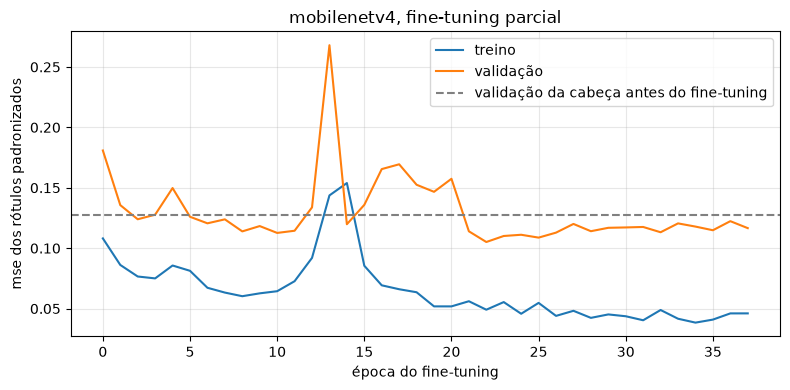

In [53]:
plt.figure(figsize=(8, 4))

plt.plot(historico_finetuning_v4.history["mse_dados"], label="treino")
plt.plot(historico_finetuning_v4.history["val_mse_dados"], label="validação")
plt.axhline(mse_cabeca_v4, color="gray", linestyle="--", label="validação da cabeça antes do fine-tuning",)

plt.xlabel("época do fine-tuning")
plt.ylabel("mse dos rótulos padronizados")
plt.title("mobilenetv4, fine-tuning parcial")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

o modelo MobileNetv4 com fine-tuning parcial foi o melhor modelo até aqui! em comparação com o melhor modelo de CNN encontrado pelo optuna treinado do zero. porém o gráfico parece mostrar um pouco de overfitting, entao é valido testar esse modelo com a mesma cabeça já ajustada mas com fine-tuning contendo data augmentation.

In [69]:
# preparar primeiro o pré-processamneto dentro do modelo
def preprocessamento_v4(tensor, usar_augmentation=False):
    interpolacao = processor_v4.resample

    if not isinstance(interpolacao, str):
        interpolacao = {
            0: "nearest",
            2: "bilinear",
            3: "bicubic",
        }[int(interpolacao)]

    x = keras.layers.Resizing(224, 224, interpolation=interpolacao, antialias=processor_v4.antialias)(tensor)
    x = keras.layers.Rescaling(processor_v4.rescale_factor)(x)

    if usar_augmentation:
        x = build_augmentation(seed=7)(x)

    # reproduz a operação usada pelo processador original
    media_imagenet = keras.ops.convert_to_tensor(processor_v4.image_mean, dtype="float32")
    desvio_imagenet = keras.ops.convert_to_tensor(processor_v4.image_std, dtype="float32")
    x = (x - media_imagenet) / desvio_imagenet

    return x

In [70]:
entrada_preprocessamento = keras.Input(shape=(256, 256, 3))

modelo_preprocessamento = keras.Model(entrada_preprocessamento, preprocessamento_v4(entrada_preprocessamento))

pixels_val_v4 = np.stack([io.imread(caminho) for caminho in df_val["caminho"]]).astype(np.float32)

modelo_preprocessamento.jit_compile = False
processamento_conferido = modelo_preprocessamento.predict(pixels_val_v4, batch_size=16, verbose=0)

print("maior diferença no pré-processamento:", np.max(np.abs(processamento_conferido - X_val_v4)))

maior diferença no pré-processamento: 0.0


In [71]:
# função para exportar o modelo v4 atual
def exportar_v4_atual():
    # copia o grafo convolucional sem a classe específica do zeromodels
    grafo_backbone = keras.Model(backbone_v4.input, backbone_v4.output, name="backbone_v4")

    copia_backbone = keras.models.clone_model(grafo_backbone)
    copia_backbone.set_weights(backbone_v4.get_weights())

    entrada = keras.Input(shape=(256, 256, 3), dtype="float32", name="imagem_pixels_0_255")

    x = preprocessamento_v4(entrada)
    x = copia_backbone(x, training=False)

    # copia pooling, dense, dropout e saída com os pesos atuais
    for camada in modelo_v4.layers:
        if (isinstance(camada, keras.layers.InputLayer) or camada is backbone_v4):
            continue

        copia = keras.layers.deserialize(keras.layers.serialize(camada))
        x = copia(x)
        copia.set_weights(camada.get_weights())

    saida = keras.layers.Normalization(axis=-1, mean=media_y.tolist(), variance=(desvio_y ** 2).tolist(), invert=True, name="altura_cm_peso_kg")(x)

    modelo = keras.Model(entrada, saida, name="bovinos_mobilenetv4")
    modelo.jit_compile = False

    return modelo

In [76]:
def prever_direto(modelo, imagens, batch_size=16):
    # executa em lotes, com dropout desativado e sem usar predict
    previsoes = []

    for inicio in range(0, len(imagens), batch_size):
        lote = imagens[inicio:inicio + batch_size]
        saida = modelo(lote, training=False)
        previsoes.append(keras.ops.convert_to_numpy(saida))

    return np.concatenate(previsoes, axis=0)

In [77]:
modelo_v4.set_weights(pesos_finetuning_v4)
exportacao_v4 = exportar_v4_atual()

# compara original e exportação pela mesma execução direta
previsoes_original_direto = desnormaliza_rotulos(prever_direto(modelo_v4, X_val_v4))
previsoes_exportacao_v4 = prever_direto(exportacao_v4, pixels_val_v4)

np.testing.assert_allclose(previsoes_original_direto, previsoes_exportacao_v4, atol=1e-4)

pasta_modelo = Path("modelos")
pasta_modelo.mkdir(exist_ok=True)

caminho_v4_sem_aug = pasta_modelo / "mobilenetv4_sem_aug.keras"
exportacao_v4.save(caminho_v4_sem_aug)

modelo_v4_sem_aug = keras.models.load_model(caminho_v4_sem_aug, compile=False)
modelo_v4_sem_aug.jit_compile = False

previsoes_v4_sem_aug = prever_direto(modelo_v4_sem_aug, pixels_val_v4)

np.testing.assert_allclose(previsoes_exportacao_v4, previsoes_v4_sem_aug, atol=1e-4)

In [81]:
def build_augmentation(seed=7):
    return keras.Sequential([
        keras.layers.RandomContrast(factor=0.1, seed=seed),
        keras.layers.RandomBrightness(factor=0.05, value_range=(0.0, 1.0), seed=seed + 1),
        keras.layers.RandomFlip(mode="horizontal",seed=seed + 2),
    ], name="augmentation")

In [82]:
# teste com augmentation, voltando aos mesmos pesos da cabeça tunados.
modelo_v4.set_weights(pesos_cabeca_v4)
keras.utils.set_random_seed(7)

entrada_aug_v4 = keras.Input(shape=(256, 256, 3), name="imagem_pixels_0_255")
x = preprocessamento_v4(entrada_aug_v4, usar_augmentation=True)

# sem training=False aqui já que o dropout da cabeça deve atuar no treino, o backbone já foi conectado com training=False dentro de modelo_v4
saida_aug_v4 = modelo_v4(x)

modelo_v4_aug = keras.Model(entrada_aug_v4, saida_aug_v4, name="mobilenetv4_treino_aug")

pixels_train_v4 = np.stack([io.imread(caminho) for caminho in df_treino["caminho"]]).astype(np.float32)

modelo_v4_aug.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), loss=criar_mse_ponderado(2.0), metrics=[keras.metrics.MeanSquaredError(name="mse_dados")], jit_compile=False)

In [83]:
callbacks_v4_aug = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_mse_dados", mode="min", factor=0.5, patience=5, min_lr=1e-7, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_mse_dados", mode="min", patience=15, restore_best_weights=True, verbose=1)
]

inicio_v4_aug = perf_counter()

historico_v4_aug = modelo_v4_aug.fit(pixels_train_v4, y_train_norm, validation_data=(pixels_val_v4, y_val_norm), 
                                     epochs=120, batch_size=16, shuffle=True, callbacks=callbacks_v4_aug, verbose=2)

tempo_v4_aug = perf_counter() - inicio_v4_aug

pesos_finetuning_v4_aug = modelo_v4.get_weights()

Epoch 1/120
29/29 - 9s - 309ms/step - loss: 0.1230 - mse_dados: 0.1367 - val_loss: 0.1140 - val_mse_dados: 0.1277 - learning_rate: 1.0000e-05
Epoch 2/120
29/29 - 1s - 36ms/step - loss: 0.1221 - mse_dados: 0.1322 - val_loss: 0.1068 - val_mse_dados: 0.1191 - learning_rate: 1.0000e-05
Epoch 3/120
29/29 - 1s - 34ms/step - loss: 0.0910 - mse_dados: 0.1022 - val_loss: 0.1188 - val_mse_dados: 0.1379 - learning_rate: 1.0000e-05
Epoch 4/120
29/29 - 1s - 34ms/step - loss: 0.0764 - mse_dados: 0.0899 - val_loss: 0.1087 - val_mse_dados: 0.1197 - learning_rate: 1.0000e-05
Epoch 5/120
29/29 - 1s - 34ms/step - loss: 0.0842 - mse_dados: 0.0995 - val_loss: 0.1297 - val_mse_dados: 0.1548 - learning_rate: 1.0000e-05
Epoch 6/120
29/29 - 1s - 33ms/step - loss: 0.0873 - mse_dados: 0.1013 - val_loss: 0.1126 - val_mse_dados: 0.1279 - learning_rate: 1.0000e-05
Epoch 7/120

Epoch 7: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
29/29 - 1s - 33ms/step - loss: 0.0735 - mse_dados: 0.0854 - val_

In [84]:
# avaliar, salvar e comparar com os três melhores modelos

previsoes_v4_aug_norm = modelo_v4_aug.predict(pixels_val_v4, batch_size=16, verbose=0)
previsoes_v4_aug = desnormaliza_rotulos(previsoes_v4_aug_norm)
mae_aug_v4, rmse_aug_v4, r2_aug_v4 = avalia_predicao(y_val, previsoes_v4_aug)

metricas_v4_aug = pd.DataFrame({
    "variável": ["altura", "peso"],
    "unidade": ["cm", "kg"],
    "mae": mae_aug_v4,
    "rmse": rmse_aug_v4,
    "r2": r2_aug_v4,
})

pd.concat([
    metricas_final.assign(modelo="cnn própria"),
    metricas_finetuning_v4.assign(modelo="v4 sem augmentation"),
    metricas_v4_aug.assign(modelo="v4 com augmentation"),
], ignore_index=True)

,variável,unidade,mae,rmse,r2,modelo
0,altura,cm,2.491505,3.201117,0.733635,cnn própria
1,peso,kg,18.181645,22.927066,0.568191,cnn própria
2,altura,cm,2.388623,3.018685,0.763131,v4 sem augmentation
3,peso,kg,17.556013,21.887159,0.606474,v4 sem augmentation
4,altura,cm,2.579679,3.269548,0.722126,v4 com augmentation
5,peso,kg,17.234972,21.408967,0.623482,v4 com augmentation


In [85]:
exportacao_v4_aug = exportar_v4_atual()
caminho_v4_aug = pasta_modelo / "mobilenetv4_com_aug.keras"

previsoes_exportacao_v4_aug = exportacao_v4_aug.predict(pixels_val_v4, batch_size=16, verbose=0)

np.testing.assert_allclose(previsoes_v4_aug, previsoes_exportacao_v4_aug, rtol=0, atol=1e-2)

exportacao_v4_aug.save(caminho_v4_aug)

modelo_v4_aug_carregado = keras.models.load_model(caminho_v4_aug, compile=False)
modelo_v4_aug_carregado.jit_compile = False

previsoes_v4_aug_carregado = modelo_v4_aug_carregado.predict(pixels_val_v4, batch_size=16, verbose=0)

np.testing.assert_allclose(previsoes_exportacao_v4_aug, previsoes_v4_aug_carregado, atol=1e-4)

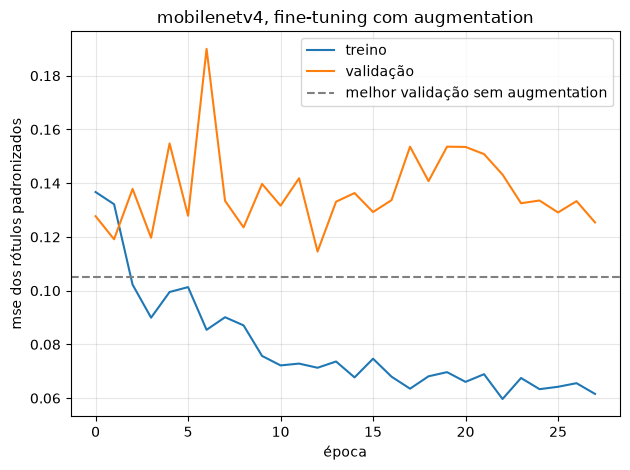

In [86]:
plt.plot(historico_v4_aug.history["mse_dados"], label="treino")
plt.plot(historico_v4_aug.history["val_mse_dados"], label="validação")
plt.axhline(mse_finetuning_v4, color="gray", linestyle="--", label="melhor validação sem augmentation")
plt.xlabel("época")
plt.ylabel("mse dos rótulos padronizados")
plt.title("mobilenetv4, fine-tuning com augmentation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [87]:
arquivos_finais = {
    "cnn própria": Path("modelos/cnn_bovinos_final.keras"),
    "v4 sem augmentation": Path("modelos/mobilenetv4_sem_aug.keras"),
    "v4 com augmentation": Path("modelos/mobilenetv4_com_aug.keras"),
}

previsoes_arquivos = {}
linhas_metricas = []
linhas_ranking = []

for nome, caminho in arquivos_finais.items():
    modelo = keras.models.load_model(caminho, compile=False)

    previsoes = prever_direto(modelo, pixels_val_v4)
    previsoes_arquivos[nome] = previsoes

    mae, rmse, r2 = avalia_predicao(y_val, previsoes)

    mse_padronizado = np.mean(((previsoes.astype(np.float64) - y_val) / desvio_y) ** 2)

    linhas_ranking.append({
        "modelo": nome,
        "parametros": modelo.count_params(),
        "mse_padronizado": mse_padronizado,
    })

    for indice, variavel, unidade in [(0, "altura", "cm"), (1, "peso", "kg")]:
        linhas_metricas.append({
            "modelo": nome,
            "variável": variavel,
            "unidade": unidade,
            "mae": mae[indice],
            "rmse": rmse[indice],
            "r2": r2[indice],
        })

    del modelo

ranking_final = pd.DataFrame(linhas_ranking).sort_values("mse_padronizado")
comparacao_arquivos = pd.DataFrame(linhas_metricas)

In [88]:
ranking_final

,modelo,parametros,mse_padronizado
1,v4 sem augmentation,1345826,0.105117
2,v4 com augmentation,1345826,0.114587
0,cnn própria,3887202,0.117120


In [89]:
comparacao_arquivos

,modelo,variável,unidade,mae,rmse,r2
0,cnn própria,altura,cm,2.491548,3.201185,0.733624
1,cnn própria,peso,kg,18.180840,22.927204,0.568186
2,v4 sem augmentation,altura,cm,2.389304,3.020129,0.762904
3,v4 sem augmentation,peso,kg,17.539919,21.867568,0.607178
4,v4 com augmentation,altura,cm,2.580804,3.270316,0.721995
5,v4 com augmentation,peso,kg,17.232032,21.404017,0.623656


modelo escolhido: v4 sem augmentation


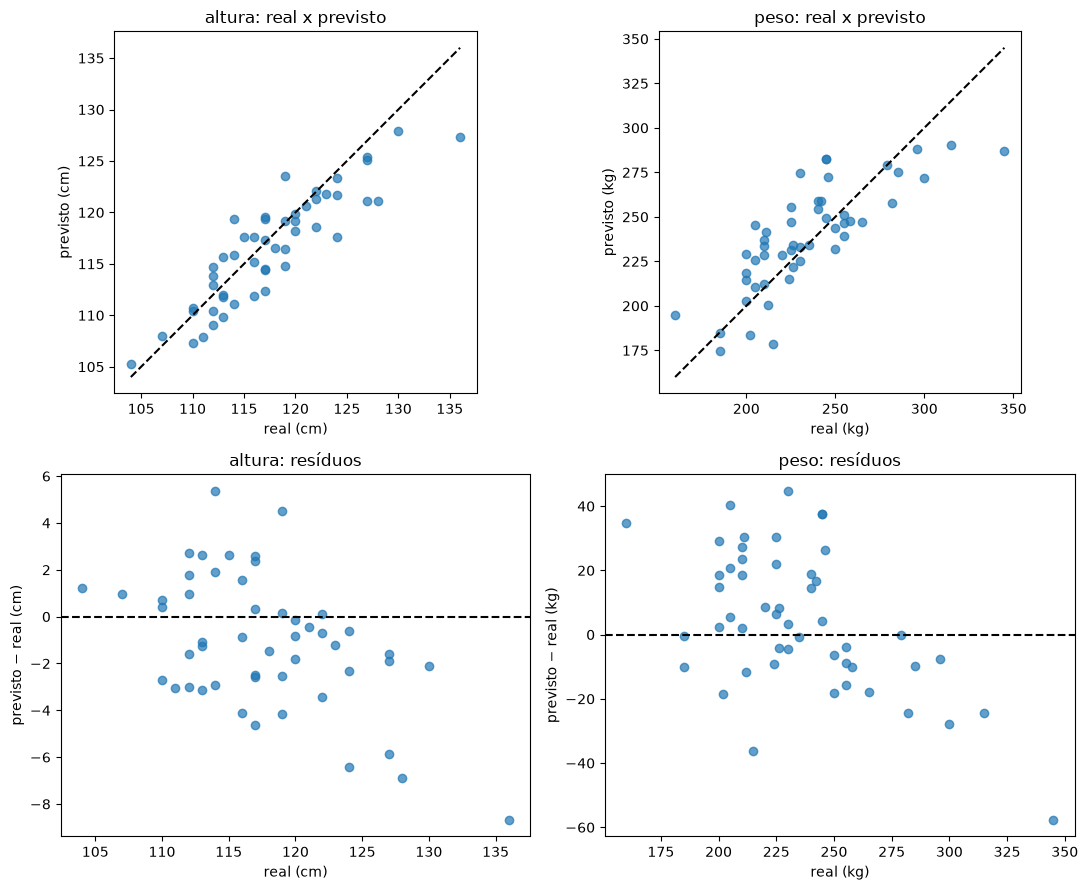

erro médio com sinal [cm, kg]: [-1.0702274  4.383266 ]


In [90]:
nome_escolhido = ranking_final.iloc[0]["modelo"]
previsoes_escolhidas = previsoes_arquivos[nome_escolhido]

print("modelo escolhido:", nome_escolhido)

fig, eixos = plt.subplots(2, 2, figsize=(11, 9))

for coluna, nome, unidade in [(0, "altura", "cm"), (1, "peso", "kg")]:
    real = y_val[:, coluna]
    previsto = previsoes_escolhidas[:, coluna]
    erro = previsto - real

    limites = [min(real.min(), previsto.min()), max(real.max(), previsto.max())]

    eixos[0, coluna].scatter(real, previsto, alpha=0.7)
    eixos[0, coluna].plot(limites, limites, "k--")
    eixos[0, coluna].set(
        title=f"{nome}: real x previsto",
        xlabel=f"real ({unidade})",
        ylabel=f"previsto ({unidade})",
    )
    eixos[0, coluna].set_aspect("equal", adjustable="box")

    eixos[1, coluna].scatter(real, erro, alpha=0.7)
    eixos[1, coluna].axhline(0, color="black", linestyle="--")
    eixos[1, coluna].set(
        title=f"{nome}: resíduos",
        xlabel=f"real ({unidade})",
        ylabel=f"previsto − real ({unidade})",
    )

plt.tight_layout()
plt.show()

print("erro médio com sinal [cm, kg]:", (previsoes_escolhidas - y_val).mean(axis=0))

na validação, o modelo apresentou erro médio com sinal de aproximadamente -1,07 cm para altura e +4,38 kg para peso, indicando tendência média de subestimar a altura e superestimar o peso.

## Conclusão e modelo final escolhido

encerramos os experimentos escolhendo a mobilenetv4-conv-small com fine-tuning parcial, sem augmentation. a escolha é baseada no menor MSE conjunto dos rótulos padronizados na validação, calculado a partir dos arquivos salvos pelo mesmo caminho de inferência.

o modelo possui 1.345.826 parâmetros, aproximadamente 65% menos que a CNN própria, com 3.887.202 parâmetros. nessa avaliação, o transfer learning melhorou os erros das duas tarefas em relação à CNN treinada do zero.

o augmentation durante o fine-tuning melhorou a estimativa do peso, mas piorou a altura e o critério conjunto. então, mantivemos a versão sem augmentation.

as curvas mostram sinais de overfitting nas épocas finais. usamos early stopping para recuperar os pesos da melhor época de validação. a cabeça usa dropout, enquanto os estágios iniciais e as camadas de batch normalization do backbone permaneceram congelados.

o arquivo do modelo final escolhido incorpora redimensionamento, normalização dos pixels e transformação das saídas para cm e kg. ele pode ser carregado para inferência sem executar os experimentos anteriores.

### Predição em imagens sem anotações e exportação do csv

parte do trabalho de carregar o modelo salvo e gerar uma previsão para cada imagem da pasta de teste, sem consultar rótulos. o id será o nome do arquivo sem a extensão. as saídas serão exportadas em cm e kg.

para executar apenas a inferência, execute as células dessa seção. para o teste por hyperlink, execute a função de predição da pasta, a função de download e a célula com o endereço do dataset. não é necessário executar o treinamento ou as buscas anteriores.

In [93]:
# dependências para executar somente a seção de inferência do teste!
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from tempfile import TemporaryDirectory
import numpy as np
import pandas as pd
import tensorflow as tf
from skimage import io
from IPython.display import display

# o modelo recebe pixels de 0 a 255 e retorna altura em cm e peso em kg
caminho_modelo = Path("modelos/mobilenetv4_sem_aug.keras")

In [94]:
def prever_pasta_imagens(modelo, pasta_imagens_teste, caminho_csv, batch_size=16):
    pasta_imagens_teste = Path(pasta_imagens_teste)

    caminhos = sorted(
        caminho
        for caminho in pasta_imagens_teste.iterdir()
        if caminho.is_file()
        and not caminho.name.startswith(".")
        and caminho.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    if not caminhos:
        raise ValueError("nenhuma imagem encontrada")

    ids = [caminho.stem for caminho in caminhos]

    if len(set(ids)) != len(ids):
        raise ValueError("ids duplicados")

    batch_previsoes = []

    for inicio in range(0, len(caminhos), batch_size):
        imagens = []

        for caminho in caminhos[inicio:inicio + batch_size]:
            imagem = io.imread(caminho)

            if imagem.shape != (256, 256, 3):
                raise ValueError(f"formato inesperado em {caminho.name}: {imagem.shape}")

            imagens.append(imagem)

        # o modelo exportado normaliza os pixels internamente
        lote = np.stack(imagens).astype(np.float32)

        batch_previsoes.append(np.asarray(modelo(lote, training=False)))

    previsoes = np.concatenate(batch_previsoes, axis=0)

    tabela = pd.DataFrame({
        "id": ids,
        "altura_cm": previsoes[:, 0],
        "peso_kg": previsoes[:, 1],
    })

    caminho_csv = Path(caminho_csv)
    caminho_csv.parent.mkdir(parents=True, exist_ok=True)
    tabela.to_csv(caminho_csv, index=False)

    return tabela

In [95]:
# teste dessa função usando as imagens que temos

modelo_teste_inferencia = tf.keras.models.load_model(caminho_modelo, compile=False)

teste_inferencia = prever_pasta_imagens(modelo_teste_inferencia, Path("images"), "predicoes/teste_local.csv")

display(teste_inferencia.head())
print("imagens previstas:", len(teste_inferencia))

,id,altura_cm,peso_kg
0,001,121.779579,278.982422
1,002,127.909050,288.371368
2,003,110.387512,200.264038
3,004,110.421661,183.377106
4,005,119.373734,210.550293


imagens previstas: 514


### Carregamento do conjunto de teste por hyperlink

o arquivo será baixado e extraído em uma pasta temporária, separada dos dados de treinamento. depois carregaremos o modelo salvo e exportaremos as previsões de todas as imagens.

In [96]:
def prever_dataset_url(url_dataset, caminho_csv):
    with TemporaryDirectory(prefix="teste_bovinos_") as temporario:
        pasta_temporaria = Path(temporario)
        arquivo_zip = pasta_temporaria / "dataset.zip"
        pasta_extraida = pasta_temporaria / "dados"

        urlretrieve(url_dataset, arquivo_zip)

        with ZipFile(arquivo_zip) as zip_dataset:
            raiz = pasta_extraida.resolve()

            # verifica se os arquivos permanecem na pasta de extração
            for membro in zip_dataset.infolist():
                destino = (raiz / membro.filename).resolve()

                if not destino.is_relative_to(raiz):
                    raise ValueError("caminho inválido dentro do zip")

            zip_dataset.extractall(pasta_extraida)

        pastas_images = [pasta for pasta in pasta_extraida.rglob("images") if pasta.is_dir() and "__MACOSX" not in pasta.parts]

        if len(pastas_images) != 1:
            raise ValueError("era esperado um único diretório images")

        modelo = tf.keras.models.load_model(caminho_modelo, compile=False)

        return prever_pasta_imagens(modelo, pastas_images[0], caminho_csv)

In [97]:
url_dataset_teste = ""  # preencher aqui o link do dataset de teste

if url_dataset_teste:
    predicoes_teste = prever_dataset_url(url_dataset_teste, "predicoes/predicoes_teste.csv",)

    display(predicoes_teste.head())
    print("previsões exportadas:", len(predicoes_teste))
else:
    print("sem hyperlink do conjunto de teste")

sem hyperlink do conjunto de teste
